In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from scipy.integrate import odeint
from scipy.linalg import solve_continuous_lyapunov

In [2]:
def covariance_modes(covariances):
    C=np.asarray(covariances,float)
    n,p=C.shape[:2]
    vals=np.full((n,p),np.nan);vectors=np.full((n,p),np.nan)
    finite=np.isfinite(C).all(axis=(1,2))
    if finite.any():
        lam,V=np.linalg.eigh((C[finite]+C[finite].transpose(0,2,1))/2)
        vals[finite]=np.maximum(lam,0);vectors[finite]=V[:,:,-1]
    leading=vals[:,-1];norm=np.linalg.norm(vals,axis=1)
    q=np.divide(leading,norm,out=np.full(n,np.nan),where=norm>0)
    vectors[leading==0]=np.nan
    angle=np.full(n,np.nan)
    if n>1:
        cosine=np.abs(np.einsum("ti,ti->t",vectors[:-1],vectors[1:]))
        angle[1:]=np.arccos(np.clip(cosine,0,1))
    return {"lambda1":leading,"normalised_l2":q,"gap":leading-vals[:,-2],
            "vector":vectors,"angle":angle}

In [3]:
simulation_path = Path("Cluster_Results")
old_figure_path = Path("Figures")
rev_figs = Path("Rev_Figures")
old_figure_path.mkdir(parents=True, exist_ok=True)
rev_figs.mkdir(parents=True, exist_ok=True)

rolling_samples = 1.0
rolling_windows = (7, 10, 14)
detrend_methods = ("window_mean", "theory", "ensemble", "spatial")
quantiles = (0.025, 0.5, 0.975)

# One total-infectious peak sets one common shift for all cities in each run.
# Alternatively set peak_reference to 1, 2, or 3 for that city's peak.
peak_reference = "total"
peak_plot_days = 20.0

qs_stab_tol = 1e-8
qs_res_tol = 1e-7
run_review_figs = True
save_new_figs = True
save_rev_tables = False

In [4]:
def symmetric_matrix(theta):
    theta = np.asarray(theta, dtype=float).ravel()
    n = int((np.sqrt(1 + 8 * theta.size) - 1) / 2)
    matrix = np.zeros((n, n))
    matrix[np.triu_indices(n)] = theta
    return matrix + matrix.T - np.diag(np.diag(matrix))


def extract_theta(matrix):
    matrix = np.asarray(matrix, dtype=float)
    return matrix[np.triu_indices(matrix.shape[0])].copy()


def covariance_summary(covariance):
    covariance = np.asarray(covariance, dtype=float)
    shape = covariance.shape[:-2]
    k = covariance.shape[-1]
    flat = covariance.reshape(-1, k, k)
    eigenvalues = np.full((len(flat), k), np.nan)
    vectors = np.full((len(flat), k), np.nan)
    finite = np.isfinite(flat).all(axis=(1, 2))
    if finite.any():
        vals, vecs = np.linalg.eigh(0.5 * (flat[finite] + flat[finite].transpose(0, 2, 1)))
        vals = np.maximum(vals, 0.0)
        eigenvalues[finite] = vals
        vectors[finite] = vecs[:, :, -1]
    norm = np.linalg.norm(eigenvalues, axis=1)
    ratio = np.full(len(flat), np.nan)
    np.divide(eigenvalues[:, -1], norm, out=ratio, where=norm > 0)
    vectors[norm == 0] = np.nan
    return {
        "eigenvalues": eigenvalues.reshape(*shape, k),
        "lambda1": eigenvalues[:, -1].reshape(shape),
        "normalised": ratio.reshape(shape),
        "eigenvector": vectors.reshape(*shape, k),
    }


def covariance_to_correlation(covariance):
    covariance = np.asarray(covariance, dtype=float)
    diagonal = np.diagonal(covariance, axis1=-2, axis2=-1)
    standard_deviation = np.sqrt(np.maximum(diagonal, 0.0))
    denominator = standard_deviation[..., :, None] * standard_deviation[..., None, :]
    correlation = np.full_like(covariance, np.nan)
    np.divide(covariance, denominator, out=correlation, where=denominator > 0)
    return correlation


def ensemble_covariance(runs, population):
    residual = (runs - runs.mean(axis=0, keepdims=True)) / np.sqrt(population)
    return np.einsum("rct,rdt->tcd", residual, residual) / (len(runs) - 1)

def interpolate_series(times, values, new_times):
    """Interpolate on the final time axis, with no extrapolation."""
    times, new_times = np.asarray(times), np.asarray(new_times)
    tol = 1e-9 * max(1.0, np.ptp(times))
    target = np.clip(new_times, times[0], times[-1])
    flat = np.asarray(values).reshape(-1, len(times))
    out = np.array([np.interp(target, times, row) for row in flat])
    return out.reshape(*np.shape(values)[:-1], len(target))


def crossing_times(times, values, level=0.0):
    times, values = np.asarray(times), np.asarray(values) - level
    roots = list(times[np.isclose(values, 0.0, atol=1e-12, rtol=0.0)])
    for i in np.flatnonzero(values[:-1] * values[1:] < 0):
        roots.append(times[i] - values[i] * (times[i + 1] - times[i]) / (values[i + 1] - values[i]))
    return np.unique(np.round(roots, 12))


def _run_array(array, n_times):
    """Normalise the pre-review saved-array layouts to (run, 3, time)."""
    array = np.asarray(array)
    if array.ndim == 3 and array.shape[1:] == (3, n_times):
        pass
    elif array.ndim == 3 and array.shape[1:] == (n_times, 3):
        array = array.transpose(0, 2, 1)
    elif array.ndim == 2 and array.shape == (n_times, 3):
        array = array.T[None, :, :]
    elif array.ndim == 2 and array.shape[1] == n_times and array.shape[0] % 3 == 0:
        array = array.reshape(-1, 3, n_times)
    elif array.ndim == 1 and array.size % (3 * n_times) == 0:
        array = array.reshape(-1, 3, n_times)
    array = np.asarray(array, dtype=float)
    return array


def load_simulation_runs(folder_name, n_times):
    folder = simulation_path / folder_name
    def files_for(prefix):
        return {p.name[1:]: p for p in sorted(folder.glob(f"{prefix}*.npy"))}
    infectious_files, susceptible_files = files_for("I"), files_for("S")
    infectious_chunks, susceptible_chunks, paths = [], [], []
    for suffix, i_path in infectious_files.items():
        s_path = susceptible_files[suffix]
        i_chunk = _run_array(np.load(i_path, mmap_mode="r", allow_pickle=False), n_times)
        s_chunk = _run_array(np.load(s_path, mmap_mode="r", allow_pickle=False), n_times)
        infectious_chunks.append(i_chunk)
        susceptible_chunks.append(s_chunk)
        paths.append({"I": str(i_path), "S": str(s_path), "runs": len(i_chunk)})
    infectious = np.concatenate(infectious_chunks, axis=0)
    susceptible = np.concatenate(susceptible_chunks, axis=0)
    return infectious, susceptible, paths

In [5]:
def jacobian_and_diffusion(S_counts, I_counts, beta, gamma, mu, population):
    s = np.asarray(S_counts, dtype=float) / population
    i = np.asarray(I_counts, dtype=float) / population
    beta = np.asarray(beta, dtype=float)
    force = beta @ i
    infection = s * force
    J_ss = np.diag(-mu - force)
    J_si = -s[:, None] * beta
    J_is = np.diag(force)
    J_ii = s[:, None] * beta - (gamma + mu) * np.eye(3)
    J = np.block([[J_ss, J_si], [J_is, J_ii]])

    B_ss = np.diag(mu * (1 - s) + infection)
    B_si = np.diag(-mu * i - infection)
    B_ii = np.diag((gamma + mu) * i + infection)
    B = np.block([[B_ss, B_si], [B_si.T, B_ii]])
    return J, B


def meta_int(X, t, betat, gamma, mu, Na):
    S, I, theta = X[:3], X[3:6], X[6:]
    beta = np.asarray(betat(t), dtype=float)
    force = (beta @ I) / Na
    dS = -force * S + (Na - S) * mu
    dI = force * S - (gamma + mu) * I
    J, B = jacobian_and_diffusion(S, I, beta, gamma, mu, Na)
    covariance = symmetric_matrix(theta)
    derivative = J @ covariance + covariance @ J.T + B
    return np.concatenate([dS, dI, extract_theta(derivative)])

$R_0=1/(\gamma+\mu)*\rho(\beta)$

In [6]:
# system parameters
gamma = 0.1
mu = 1/(80*365)
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
np.max(np.linalg.eigvals(beta_matrix))/(gamma+mu)

4.005684465099393

In [7]:
def analyze_epidemic_data(folder_name, betat, ts, gamma, mu, N_population, Si, Ii, etol):
    # etol is retained for compatibility; actual crossings are now interpolated.
    ts = np.asarray(ts, dtype=float)
    initial = np.r_[Si, Ii, np.zeros(21)]
    theory = odeint(meta_int, initial, ts, args=(betat, gamma, mu, N_population),
                    rtol=1e-8, atol=1e-10, mxstep=10000)
    full_covariance = np.array([symmetric_matrix(row[6:]) for row in theory])
    covariance = full_covariance[:, 3:, 3:]
    summary = covariance_summary(covariance)
    # Freeze each scenario's actual beta trajectory; later redefinitions of betat
    # cannot change a previously computed diagnostic.
    beta_matrices = np.array([betat(t) for t in ts], dtype=float)
    next_generation = theory[:, :3, None] * beta_matrices / (N_population * (gamma + mu))
    Reff = np.max(np.abs(np.linalg.eigvals(next_generation)), axis=-1)
    roots = crossing_times(ts, Reff, level=1.0)
    crossings = np.array([np.argmin(np.abs(ts - t)) for t in roots], dtype=int)
    infectious, susceptible, archives = load_simulation_runs(folder_name, len(ts))
    result = {
        "scenario": folder_name, "times": ts, "population": N_population,
        "gamma": gamma, "mu": mu, "beta_matrices": beta_matrices,
        "theory": theory, "full_covariance": full_covariance,
        "covariance": covariance, "eigvals": summary["lambda1"],
        "norm_eigvals": summary["normalised"], "eigvec": summary["eigenvector"],
        "Reff": Reff, "crossings": crossings, "crossing_times": roots,
        "infectious_runs": infectious, "susceptible_runs": susceptible,
        "simulation_archives": archives,
        "n_realisations": 0 if infectious is None else len(infectious),
    }
    if infectious is None:
        result.update({
            "ensemble_covariance": np.full_like(covariance, np.nan),
            "mean_per_time": np.full((3, len(ts)), np.nan),
            "I_lb": np.full((2, 3, len(ts)), np.nan),
            "sim_eigvals": np.full(len(ts), np.nan),
            "sim_norm_eigvals": np.full(len(ts), np.nan),
            "sim_eigvec": np.full((len(ts), 3), np.nan),
            "Reff_sims": np.full(len(ts), np.nan),
            "Reff_lb": np.full((2, len(ts)), np.nan),
        })
        return result

    covariance_sim = ensemble_covariance(infectious, N_population)
    summary_sim = covariance_summary(covariance_sim)
    R_runs = np.empty((len(infectious), len(ts)))
    for j, beta in enumerate(beta_matrices):
        matrices = susceptible[:, :, j, None] * beta / (N_population * (gamma + mu))
        R_runs[:, j] = np.max(np.abs(np.linalg.eigvals(matrices)), axis=-1)
    result.update({
        "ensemble_covariance": covariance_sim,
        "mean_per_time": infectious.mean(axis=0),
        "I_lb": np.quantile(infectious, [0.025, 0.975], axis=0),
        "sim_eigvals": summary_sim["lambda1"],
        "sim_norm_eigvals": summary_sim["normalised"],
        "sim_eigvec": summary_sim["eigenvector"],
        "Reff_sims": R_runs.mean(axis=0),
        "Reff_lb": np.quantile(R_runs, [0.025, 0.975], axis=0),
    })
    return result

In [ ]:
def frozen_covariance_at(J, B, stability_tol=qs_stab_tol,
                         residual_tol=qs_res_tol):
    """Solve J C + C J.T + B = 0 only for a Hurwitz-stable frozen drift."""
    J, B = np.asarray(J, dtype=float), np.asarray(B, dtype=float)
    spectral_abscissa = float(np.max(np.linalg.eigvals(J).real))
    output = {"spectral_abscissa": spectral_abscissa,
              "covariance": np.full_like(B, np.nan),
              "relative_residual": np.nan, "minimum_eigenvalue": np.nan,
              "status": "unstable_or_neutral"}
    if spectral_abscissa >= -stability_tol:
        return output
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", RuntimeWarning)
            # SciPy solves J C + C J.T = Q, hence Q = -B.
            covariance = solve_continuous_lyapunov(J, -B)
        covariance = 0.5 * (covariance + covariance.T)
        residual = np.linalg.norm(J @ covariance + covariance @ J.T + B, ord="fro")
        residual /= max(np.linalg.norm(B, ord="fro"), np.finfo(float).tiny)
        minimum = float(np.linalg.eigvalsh(covariance)[0])
        output.update(relative_residual=residual, minimum_eigenvalue=minimum)
        if caught:
            output["status"] = "solver_warning"
        elif not np.isfinite(covariance).all() or residual > residual_tol:
            output["status"] = "residual_failed"
        elif minimum < -1e-9 * max(np.linalg.norm(covariance, ord=2), np.finfo(float).tiny):
            output["status"] = "not_positive_semidefinite"
        else:
            output["status"] = "stable"
            output["covariance"] = covariance
    except (ValueError, np.linalg.LinAlgError) as exc:
        output["status"] = f"solver_failed: {type(exc).__name__}"
    return output


def quasistatic_diagnostics(result):
    n = len(result["times"])
    J_all, B_all = np.empty((n, 6, 6)), np.empty((n, 6, 6))
    covariance = np.full((n, 6, 6), np.nan)
    spectral = np.empty(n)
    infection_spectral = np.empty(n)
    numerical = np.empty(n)
    residuals = np.full(n, np.nan)
    minimums = np.full(n, np.nan)
    statuses = []
    for j, state in enumerate(result["theory"]):
        J, B = jacobian_and_diffusion(state[:3], state[3:6], result["beta_matrices"][j],
                                      result["gamma"], result["mu"], result["population"])
        J_all[j], B_all[j] = J, B
        solution = frozen_covariance_at(J, B)
        covariance[j] = solution["covariance"]
        spectral[j] = solution["spectral_abscissa"]
        infection_spectral[j] = np.max(np.linalg.eigvals(J[3:, 3:]).real)
        numerical[j] = np.linalg.eigvalsh(0.5 * (J + J.T))[-1]
        residuals[j] = solution["relative_residual"]
        minimums[j] = solution["minimum_eigenvalue"]
        statuses.append(solution["status"])
    infectious_covariance = covariance[:, 3:, 3:]
    summary = covariance_summary(infectious_covariance)
    valid = np.array(statuses) == "stable"
    ratio = np.full(n, np.nan)
    np.divide(result["eigvals"], summary["lambda1"], out=ratio,
              where=valid & (summary["lambda1"] > 0))
    denominator = np.linalg.norm(infectious_covariance, axis=(1, 2))
    frobenius_ratio = np.full(n, np.nan)
    relative_gap = np.full(n, np.nan)
    np.divide(np.linalg.norm(result["covariance"], axis=(1, 2)), denominator,
              out=frobenius_ratio, where=valid & (denominator > 0))
    np.divide(np.linalg.norm(result["covariance"] - infectious_covariance, axis=(1, 2)),
              denominator, out=relative_gap, where=valid & (denominator > 0))
    return {
        "J": J_all, "B": B_all, "full_covariance": covariance,
        "covariance": infectious_covariance, "summary": summary, "valid": valid,
        "status": np.array(statuses), "spectral_abscissa": spectral,
        "infection_block_spectral_abscissa": infection_spectral,
        "numerical_abscissa": numerical, "relative_lyapunov_residual": residuals,
        "minimum_full_covariance_eigenvalue": minimums,
        "lambda1_dynamic_over_frozen": ratio,
        "frobenius_dynamic_over_frozen": frobenius_ratio,
        "relative_matrix_gap": relative_gap,
        "infectious_noise_trace": np.trace(B_all[:, 3:, 3:], axis1=1, axis2=2),
        "jacobian_zero_crossings": crossing_times(result["times"], spectral),
    }

def plot_epidemic_results_single(results, ts, npi_time=None,save_path=None, legend=True, mini_loc="center right"):
    ts = np.asarray(ts)
    n = len(ts)
    fig, axs = plt.subplots(4, 1, figsize=(10, 18), sharex=True, constrained_layout=True)
    styles = ["solid", "dashed", "dotted"]
    colors = ["#E69F00", "#56B4E9", "#009E73"]
    for city in range(3):
        axs[0].plot(ts, results["theory"][:n, city + 3], linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[2].plot(ts, np.abs(results["eigvec"][:n, city]), linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[0].plot(ts, results["mean_per_time"][city, :n], color=colors[city], alpha=0.7, label=f"Simulation - City {city + 1}", linewidth=1)
        axs[0].fill_between(ts, *results["I_lb"][:, city, :n], color=colors[city], alpha=0.15)
        axs[2].plot(ts, np.abs(results["sim_eigvec"][:n, city]), color=colors[city], alpha=0.7, linewidth=1)
    ax0 = axs[0].twinx()
    ax0.plot(ts, results["Reff"][:n], label=r"$R_t$ - Theory", linewidth=2, color="k")
    axs[1].plot(ts, results["eigvals"][:n], label=r"$\lambda_1$ - Theory", linewidth=2)
    # Invalid frozen solutions remain NaN, leaving gaps outside stable intervals.
    frozen = quasistatic_diagnostics(results)
    axs[1].plot(ts, frozen["summary"]["lambda1"][:n], color="b",
                linestyle=":", linewidth=2, label=r"$\lambda_1$ - Quasi-static Theory")
    ax1 = axs[1].twinx()
    ax1.plot(ts, results["norm_eigvals"][:n], label=r"$\lambda_1/\|\lambda\|_2$ - Theory", linewidth=2, color = 'k')
    ax0.plot(ts, results["Reff_sims"][:n], "--", label=r"$R_t$ - Simulation", color = "r")
    ax0.fill_between(ts, *results["Reff_lb"][:, :n], alpha=0.15, color = "r")
    axs[1].plot(ts, results["sim_eigvals"][:n], "--", label=r"$\lambda_1$ - Simulation")
    ax1.plot(ts, results["sim_norm_eigvals"][:n], "--", label=r"$\lambda_1/\|\lambda\|_2$ - Simulation")
    comparisons=[("Eigenvalue gap - Theory",results["covariance"],"-")]
    comparisons.append(("Eigenvalue gap - Simulation",results["ensemble_covariance"],"--"))
    for label,C,style in comparisons:
        modes=covariance_modes(C[:n])
        axs[3].plot(ts,modes["gap"],style,label=label)
    comparisons=[("Angular Displacement - Theory",results["covariance"],"-")]
    ax3 = axs[3].twinx()
    ax3.plot(ts,covariance_modes(results["covariance"][:n])["angle"],"-",label="Angular Displacement - Theory",color="k")
    ax3.plot(ts,covariance_modes(results["ensemble_covariance"][:n])["angle"],"--",label="Angular Displacement - Simulation")
    roots = results["crossing_times"]
    for ax in axs:
        for root in roots[(roots >= ts[0]) & (roots <= ts[-1])]:
            ax.axvline(root, color="k", linestyle="--", alpha=0.6)
        if npi_time is not None and ts[0] <= npi_time <= ts[-1]:
            ax.axvline(npi_time, color="k", alpha=0.6)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=12)
    labels = ["Number infectious", r"$R_t$", r"$\lambda_1$",
              r"$\lambda_1/\|\lambda\|_2$", "Absolute dominant eigenvector",
              r"Covariance gap $\lambda_1-\lambda_2$", "Eigenvector rotation (rad)"]
    axs_label = [axs[0], ax0, axs[1], ax1, axs[2], axs[3], ax3]
    for ax, label in zip(axs_label, labels):
        ax.set_ylabel(label, fontsize=13)
    axs[0].set_ylim(bottom=0)
    axs[1].set_ylim(bottom=0)
    axs[2].set_ylim(bottom=0)
    ax1.set_ylim(0, 1.05)
    axs[2].set_ylim(0, 1.05)
    axs[-1].set_xlabel("Time (days)", fontsize=13)
    if legend:
        twin_pairs = [(axs[0], ax0), (axs[1], ax1), (axs[3], ax3)]
        for primary_ax, secondary_ax in twin_pairs:
            handles, labels_text = primary_ax.get_legend_handles_labels()
            if secondary_ax is not None:
                h2, l2 = secondary_ax.get_legend_handles_labels()
                handles += h2
                labels_text += l2
            if primary_ax == axs[1]:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="center right")
            else:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="upper right")
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Constant $\beta$

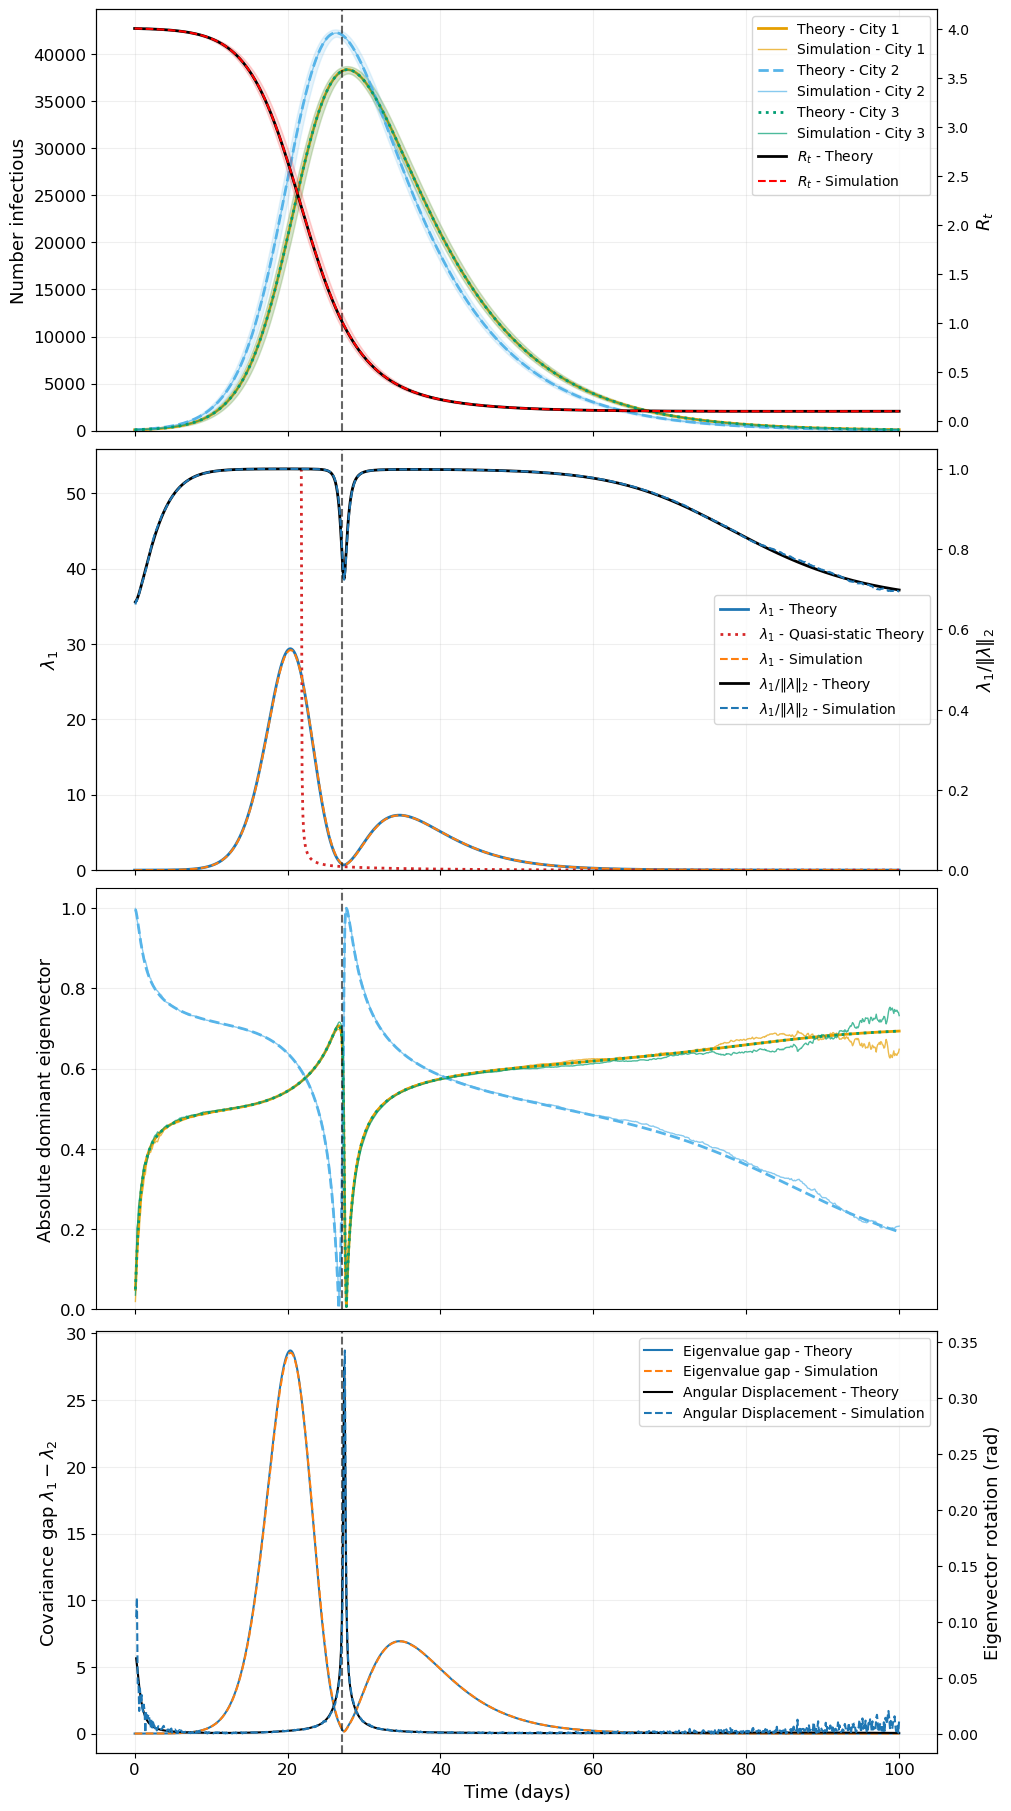

In [10]:
# parameters
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 100000

Ii = np.array([100,100,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
days = np.arange(0,101,1)
ts = np.arange(0,100.1,0.1)
results_constant = analyze_epidemic_data('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_constant, ts, save_path='Rev_Figures/cst_theory.pdf')

## Just b[1,1], full epidemic

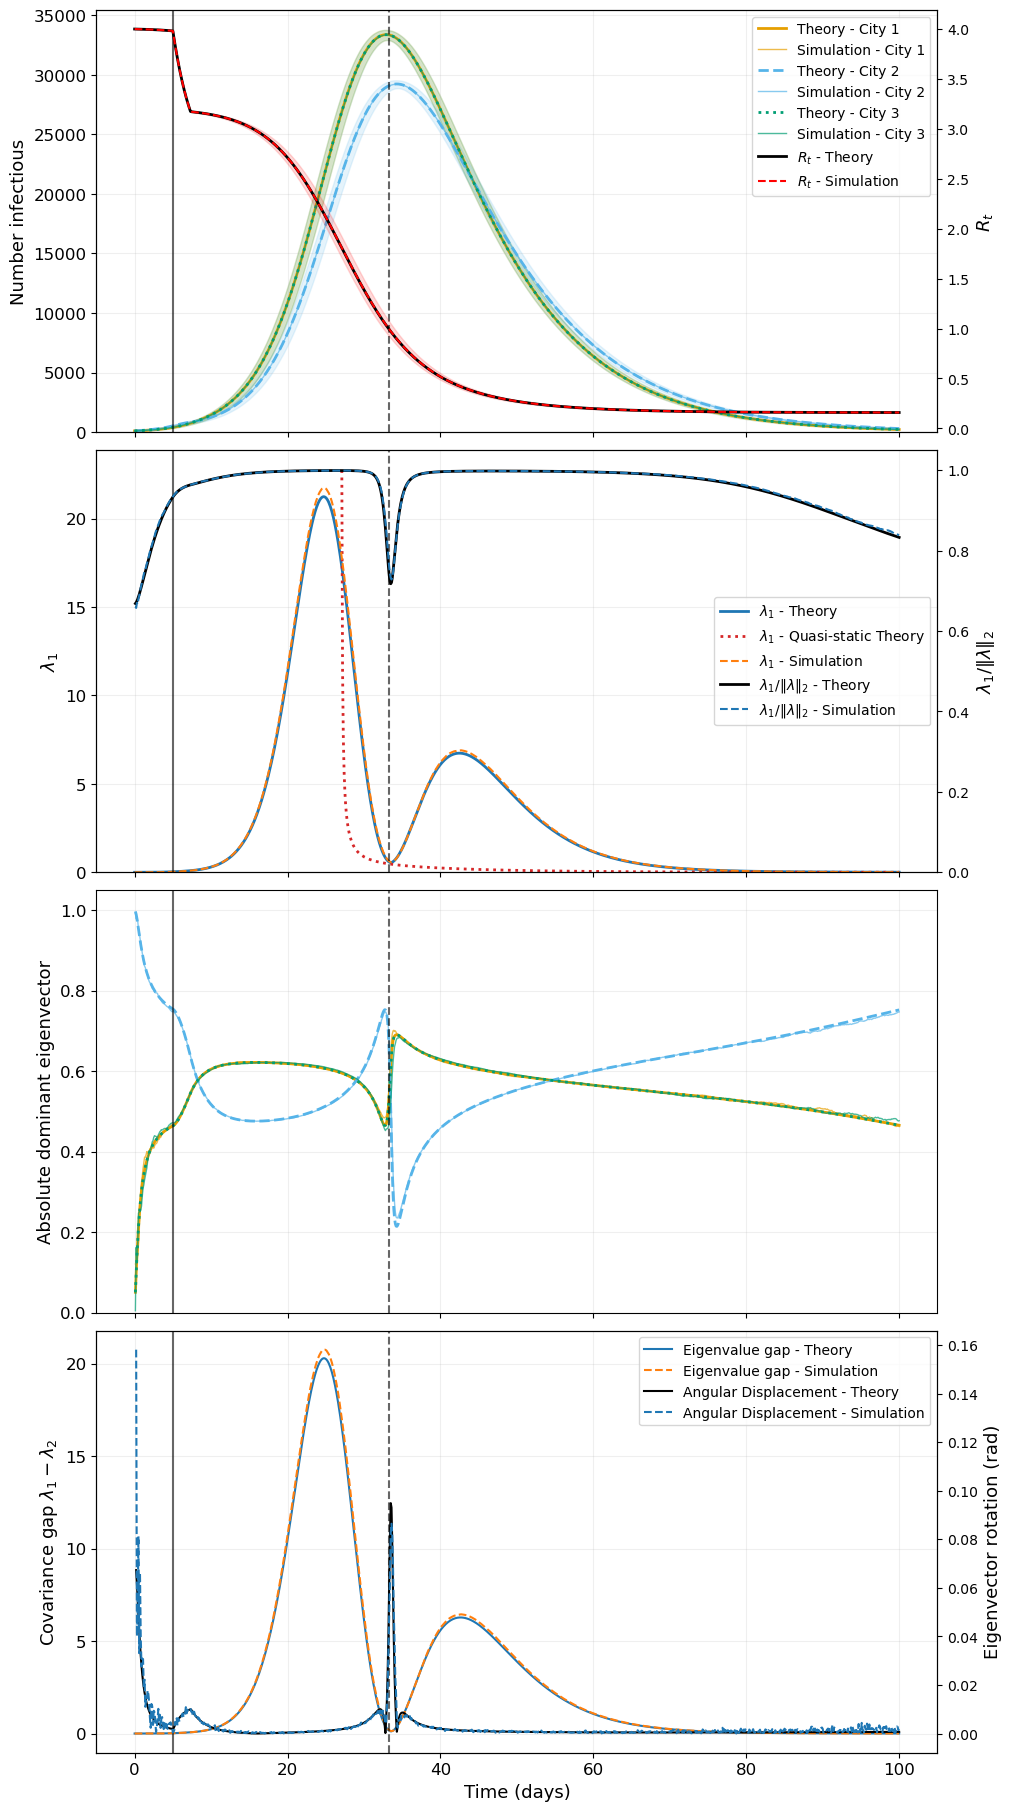

In [11]:
def betat(t):
    if t < 5:
        return beta_matrix
    else:
        temp = np.diag([0,1,0])
        return beta_matrix - 0.1*(t-5)*temp if (beta_matrix - 0.1*(t-5)*temp >= 0).all() else beta_matrix - np.diag([0,beta_matrix[1,1],0])
results_incity = analyze_epidemic_data('indec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_incity, ts, npi_time=5, save_path='Rev_Figures/in_city_theory.pdf')

## Between cities

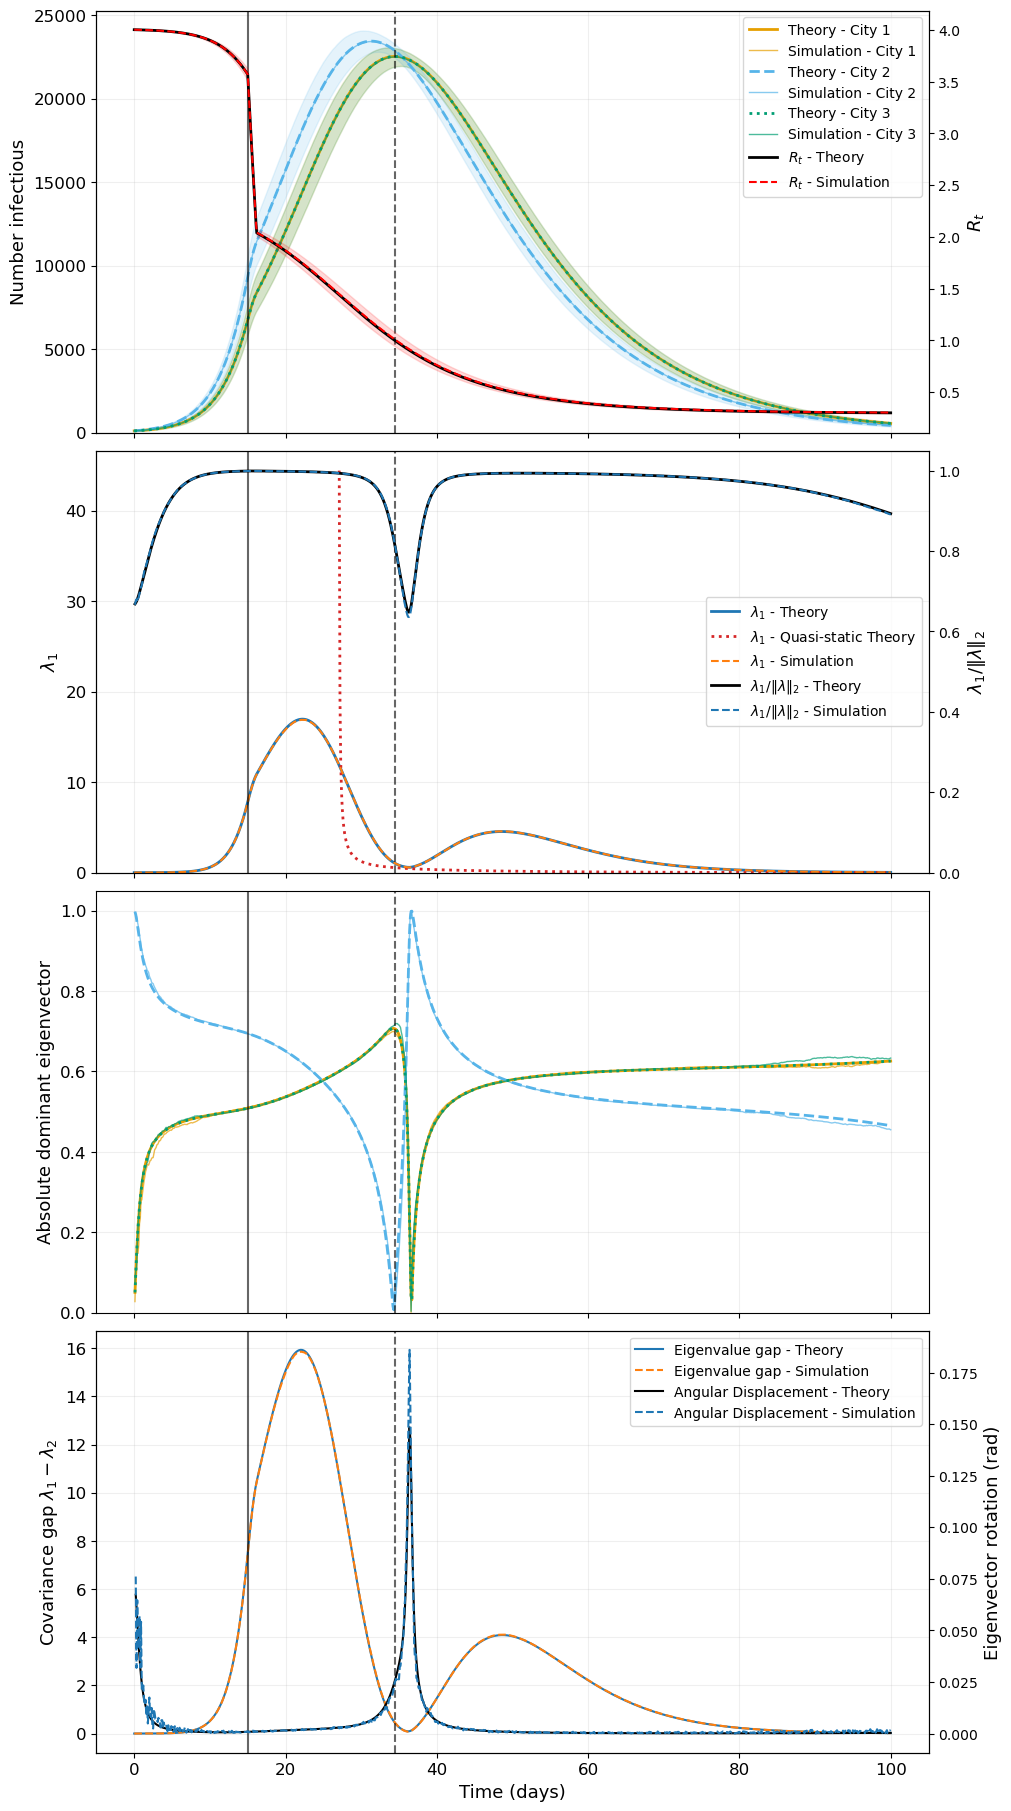

In [12]:
def betat(t):
    if t < 15:
        return beta_matrix
    else:
        temp = np.array([[0,1,0],[1,0,1],[0,1,0]])
        return beta_matrix - 0.1*(t-15)*temp if (beta_matrix - 0.1*(t-15)*temp >= 0).all() else beta_matrix - np.array([[0,b_b,0],[b_b,0,b_b],[0,b_b,0]])

results_between = analyze_epidemic_data('betdec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_between, ts, npi_time=15, save_path='Rev_Figures/bet_city_theory.pdf')

## New variant

0.8532611778611298
1.3303954541400647


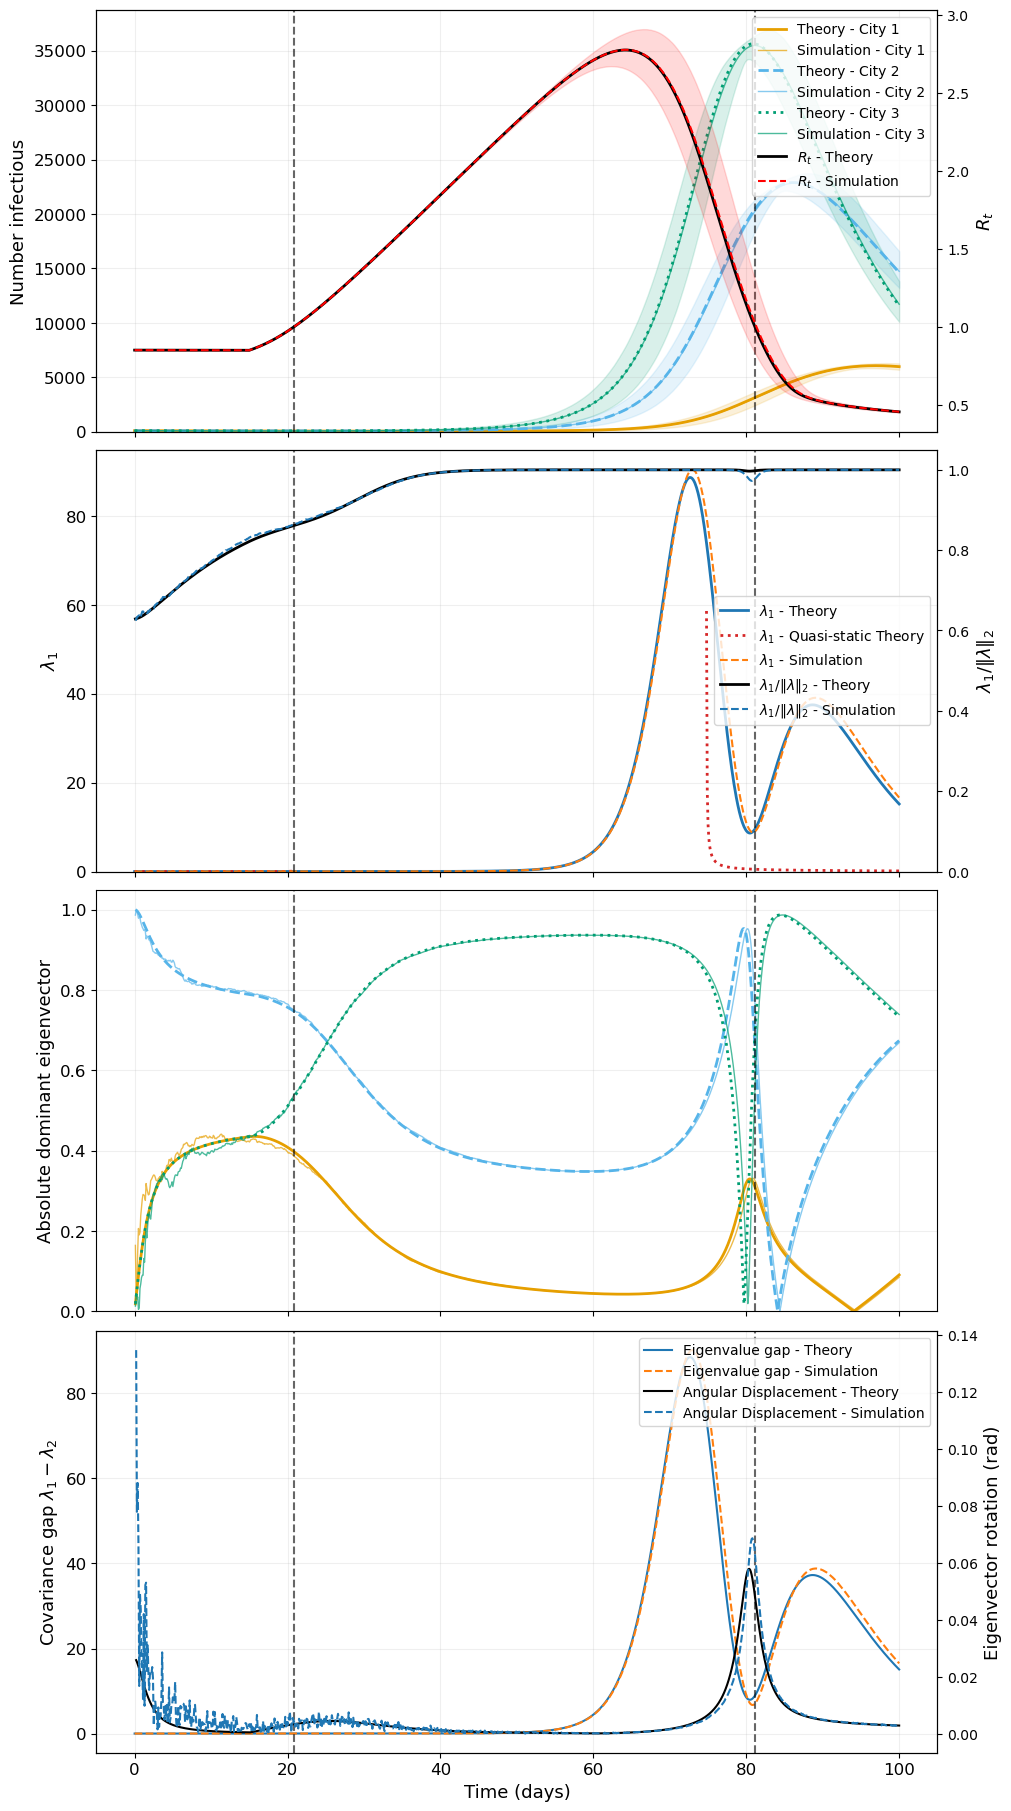

In [13]:
N_cities = 3
T_max = 100
N_population = 100000

Ii = np.array([100,100,100])
Si = N_population - Ii

def betat(t):
    b_w_l = 0.05
    b_b_l = 0.025
    beta_matrix_low = np.array([[b_w_l, b_b_l, 0],
                                [b_b_l, b_w_l, b_b_l],
                                [0,     b_b_l, b_w_l]])
    if t < 15:
        return beta_matrix_low
    else:
        temp = np.array([[0,0,0],
                         [0,0,0.25],
                         [0,0,1]])
        return beta_matrix_low + 0.005*(t-15)*temp

gamma = 0.1
mu = 1/(80*365)
b_w_l = 0.05
b_b_l = 0.025
beta_matrix_low = np.array([[b_w_l,b_b_l,0],[b_b_l,b_w_l,b_b_l],[0,b_b_l,b_w_l]])
print(np.max(np.linalg.eigvals(beta_matrix_low))/(gamma+mu))
beta_matrix_var = np.array([[b_w_l,b_b_l,0],[b_b_l,b_w_l,0.1],[0,b_b_l,0.1]])
print(np.max(np.linalg.eigvals(beta_matrix_var))/(gamma+mu))

results_nv = analyze_epidemic_data('newvar', betat, ts, gamma, mu, N_population, Si, Ii, 0.008)
plot_epidemic_results_single(results_nv, ts, save_path='Rev_Figures/new_var_theory.pdf')

In [14]:
def plot_epidemic_results_single_short(results, ts, npi_time=None,save_path=None, legend=True, ylims = False, mini_loc="center right"):
    ts = np.asarray(ts)
    n = len(ts)
    fig, axs = plt.subplots(4, 1, figsize=(10, 18), sharex=True, constrained_layout=True)
    styles = ["solid", "dashed", "dotted"]
    colors = ["#E69F00", "#56B4E9", "#009E73"]
    for city in range(3):
        axs[0].plot(ts, results["theory"][:n, city + 3], linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[2].plot(ts, np.abs(results["eigvec"][:n, city]), linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[0].plot(ts, results["mean_per_time"][city, :n], color=colors[city], alpha=0.7, label=f"Simulation - City {city + 1}", linewidth=1)
        axs[0].fill_between(ts, *results["I_lb"][:, city, :n], color=colors[city], alpha=0.15)
        axs[2].plot(ts, np.abs(results["sim_eigvec"][:n, city]), color=colors[city], alpha=0.7, linewidth=1)
    ax0 = axs[0].twinx()
    ax0.plot(ts, results["Reff"][:n], label=r"$R_t$ - Theory", linewidth=2, color="k")
    axs[1].plot(ts, results["eigvals"][:n], label=r"$\lambda_1$ - Theory", linewidth=2)
    # Invalid frozen solutions remain NaN, leaving gaps outside stable intervals.
    frozen = quasistatic_diagnostics(results)
    axs[1].plot(ts, frozen["summary"]["lambda1"][:n], color="b",
                linestyle=":", linewidth=2, label=r"$\lambda_1$ - Quasi-static Theory")
    ax1 = axs[1].twinx()
    ax1.plot(ts, results["norm_eigvals"][:n], label=r"$\lambda_1/\|\lambda\|_2$ - Theory", linewidth=2, color = 'k')
    ax0.plot(ts, results["Reff_sims"][:n], "--", label=r"$R_t$ - Simulation", color = "r")
    ax0.fill_between(ts, *results["Reff_lb"][:, :n], alpha=0.15, color = "r")
    axs[1].plot(ts, results["sim_eigvals"][:n], "--", label=r"$\lambda_1$ - Simulation")
    ax1.plot(ts, results["sim_norm_eigvals"][:n], "--", label=r"$\lambda_1/\|\lambda\|_2$ - Simulation")
    comparisons=[("Eigenvalue gap - Theory",results["covariance"],"-")]
    comparisons.append(("Eigenvalue gap - Simulation",results["ensemble_covariance"],"--"))
    for label,C,style in comparisons:
        modes=covariance_modes(C[:n])
        axs[3].plot(ts,modes["gap"],style,label=label)
    comparisons=[("Angular Displacement - Theory",results["covariance"],"-")]
    ax3 = axs[3].twinx()
    ax3.plot(ts,covariance_modes(results["covariance"][:n])["angle"],"-",label="Angular Displacement - Theory",color="k")
    ax3.plot(ts,covariance_modes(results["ensemble_covariance"][:n])["angle"],"--",label="Angular Displacement - Simulation")
    roots = results["crossing_times"]
    for ax in axs:
        for root in roots[(roots >= ts[0]) & (roots <= ts[-1])]:
            ax.axvline(root, color="k", linestyle="--", alpha=0.6)
        if npi_time is not None and ts[0] <= npi_time <= ts[-1]:
            ax.axvline(npi_time, color="k", alpha=0.6)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=12)
    labels = ["Number infectious", r"$R_t$", r"$\lambda_1$",
              r"$\lambda_1/\|\lambda\|_2$", "Absolute dominant eigenvector",
              r"Covariance gap $\lambda_1-\lambda_2$", "Eigenvector rotation (rad)"]
    axs_label = [axs[0], ax0, axs[1], ax1, axs[2], axs[3], ax3]
    for ax, label in zip(axs_label, labels):
        ax.set_ylabel(label, fontsize=13)
    axs[0].set_ylim(bottom=0)
    axs[1].set_ylim(bottom=0)
    axs[2].set_ylim(bottom=0)
    ax1.set_ylim(0, 1.05)
    axs[2].set_ylim(0, 1.05)
    axs[-1].set_xlabel("Time (days)", fontsize=13)
    if ylims:
        axs[1].set_ylim(top=ylims)
    if legend:
        twin_pairs = [(axs[0], ax0), (axs[1], ax1), (axs[3], ax3)]
        for primary_ax, secondary_ax in twin_pairs:
            handles, labels_text = primary_ax.get_legend_handles_labels()
            if secondary_ax is not None:
                h2, l2 = secondary_ax.get_legend_handles_labels()
                handles += h2
                labels_text += l2
            if primary_ax == axs[1]:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="center right")
            else:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="upper right")
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

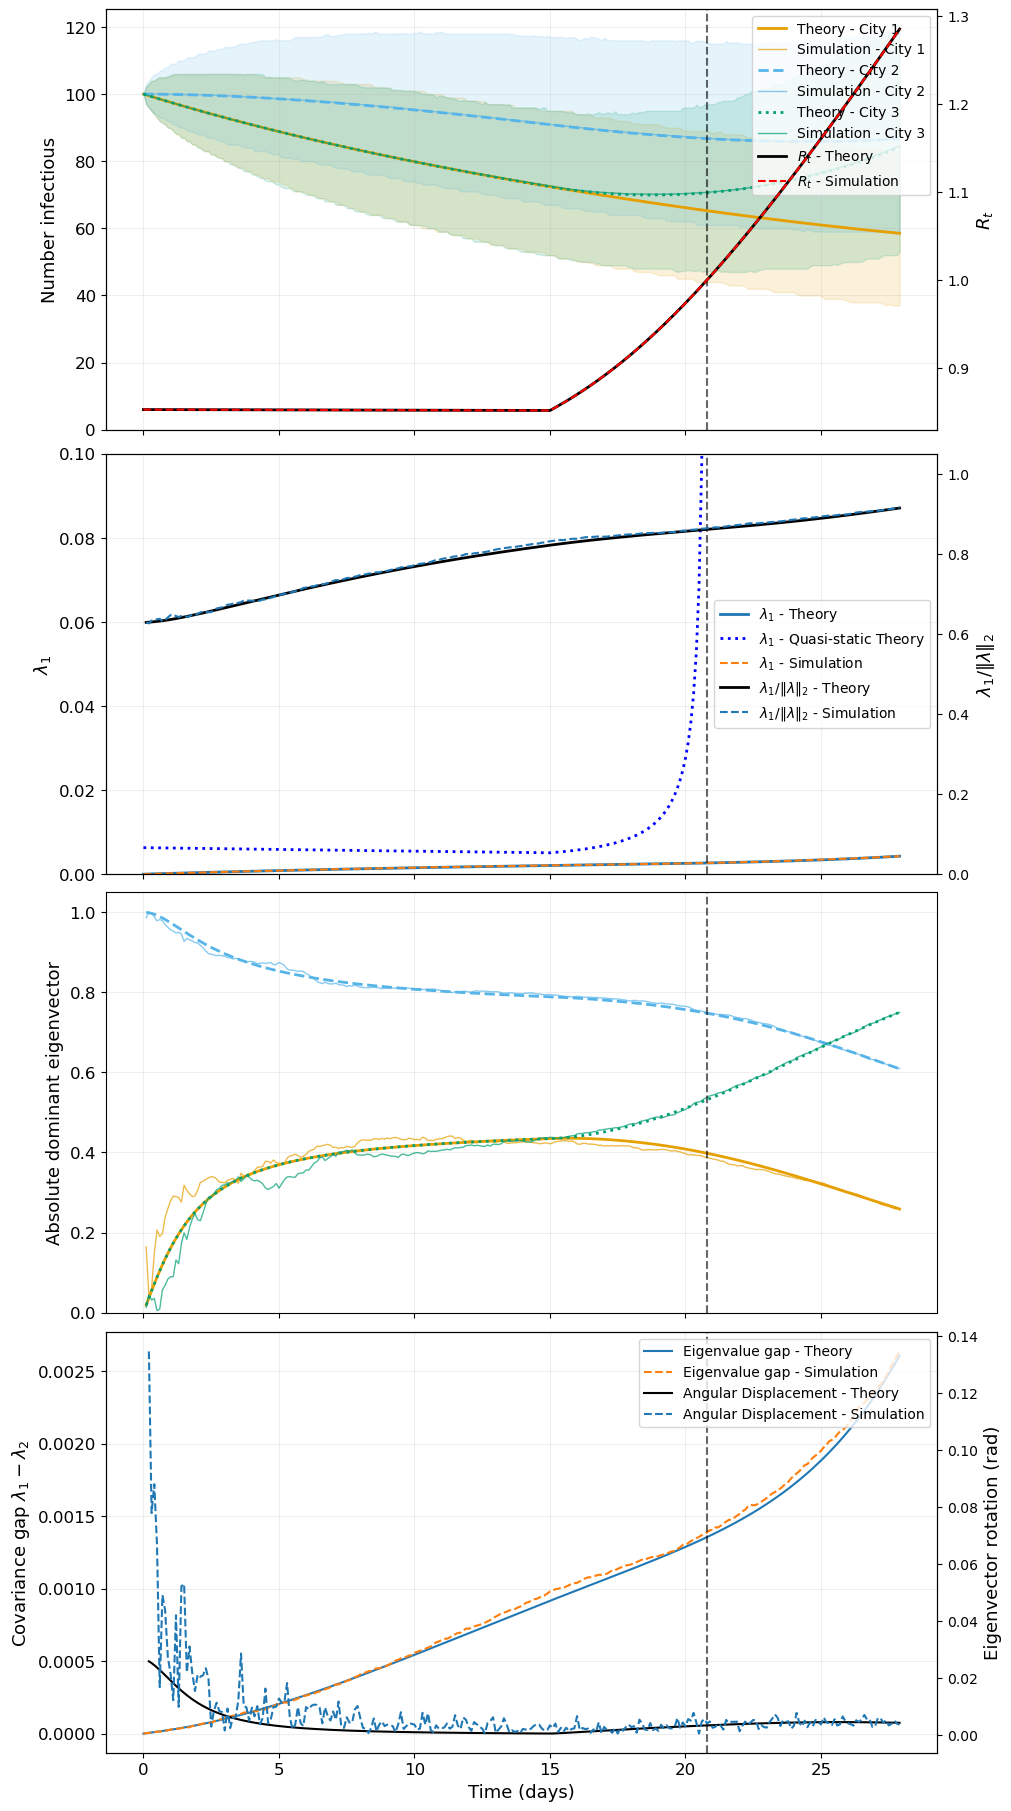

In [15]:
plot_epidemic_results_single_short(results_nv, ts[:280], ylims=0.1, save_path='Rev_Figures/new_var_theory_short.pdf')

## (Re-)Emergence

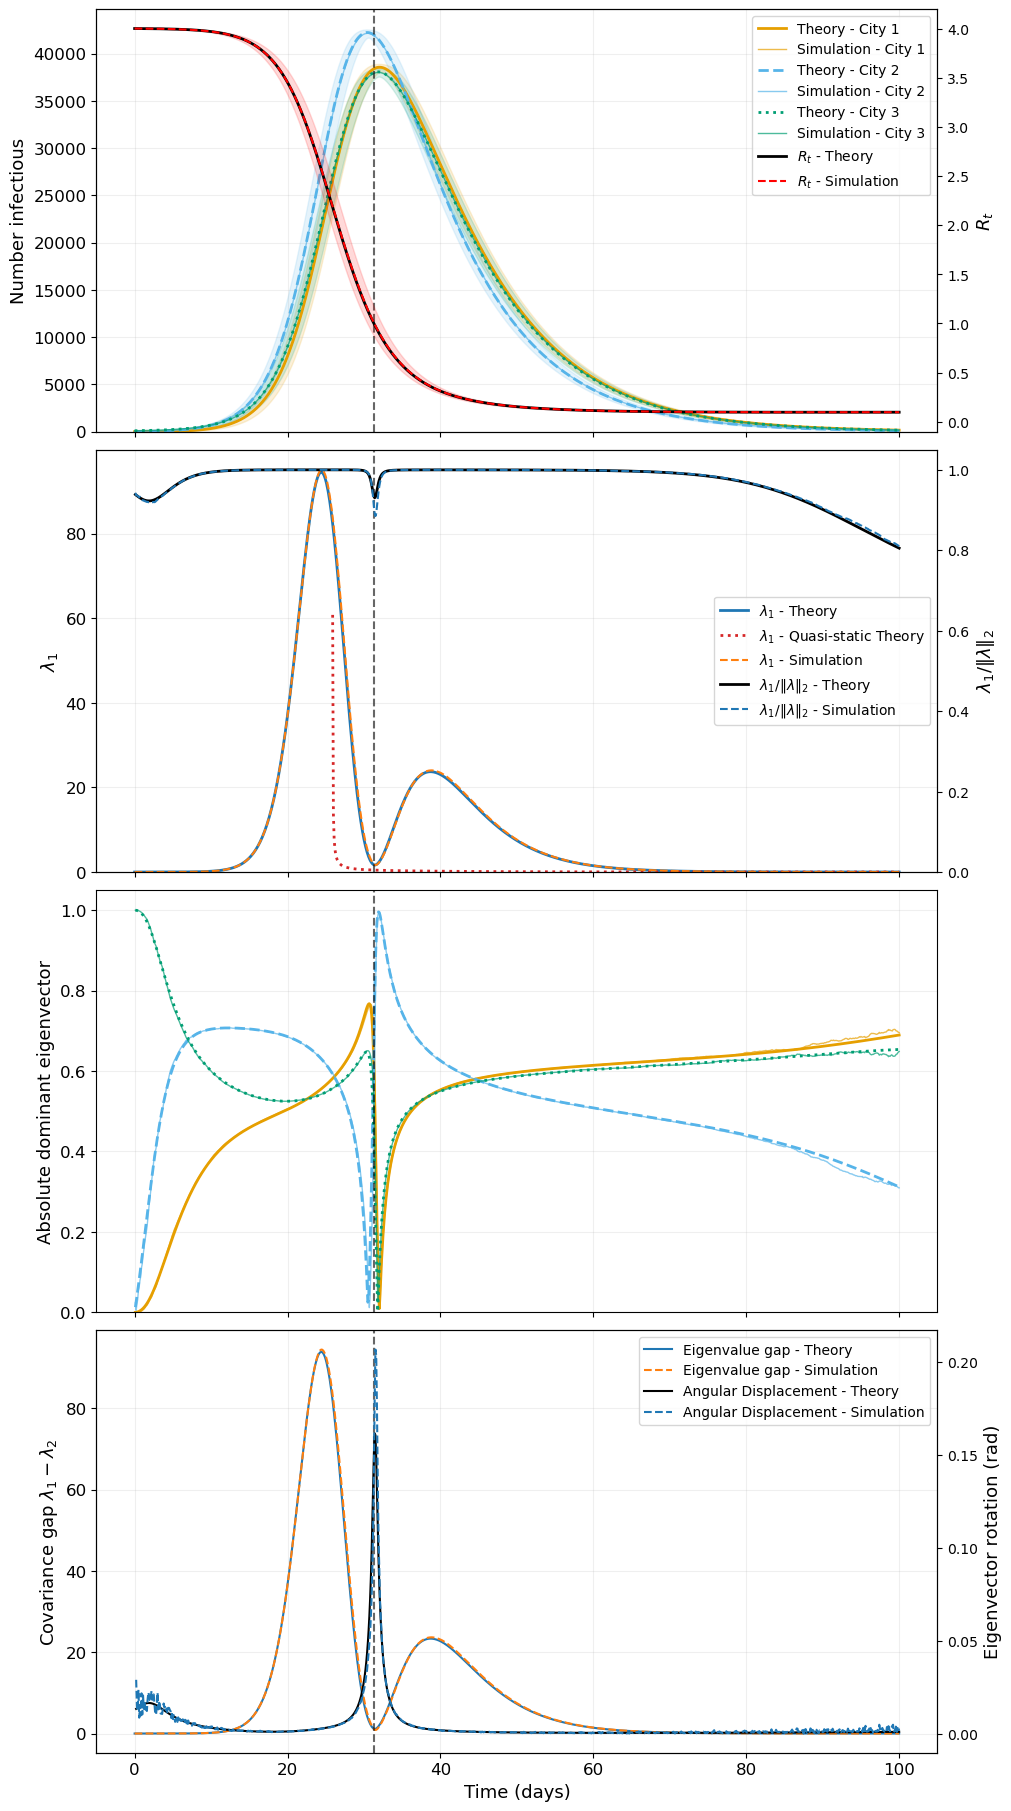

In [16]:
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 100000

Ii = np.array([0,0,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
results_seed = analyze_epidemic_data('seed', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_seed, ts, save_path='Rev_Figures/seed_theory.pdf')

In [23]:
ROLLING_LABELS = {
    "window_mean": "Window mean (single run)",
    "theory": "Deterministic trend (control)",
    "ensemble": "Ensemble trend (control)",
    "spatial": "Mean of the three cities (single run)"
}


def rolling_covariance_diagnostics(result, windows=rolling_windows,
                                   sample_days=rolling_samples,
                                   methods=detrend_methods,
                                   residual_provider=None):
    """Time covariance of each individual realisation, on complete trailing windows."""
    if result["infectious_runs"] is None:
        return {"available": False, "reason": "simulation arrays absent", "estimates": {}}
    times = result["times"]
    n_observations = int(np.floor((times[-1] - times[0]) / sample_days + 1e-9)) + 1
    observation_times = times[0] + sample_days * np.arange(n_observations)
    runs = interpolate_series(times, result["infectious_runs"], observation_times)
    count = len(runs)
    covariance_theory = np.moveaxis(interpolate_series(
        times, np.moveaxis(result["covariance"], 0, -1), observation_times), -1, 0)
    covariance_ensemble = np.moveaxis(interpolate_series(
        times, np.moveaxis(result["ensemble_covariance"], 0, -1), observation_times), -1, 0)
    deterministic = interpolate_series(times, result["theory"][:, 3:6].T, observation_times)
    methods = tuple(methods)
    estimates = {}
    for method in methods:
        if method == "window_mean":
            residual = runs / np.sqrt(result["population"])
        elif method == "theory":
            residual = (runs - deterministic[None, :, :]) / np.sqrt(result["population"])
        elif method == "ensemble":
            residual = (runs - runs.mean(axis=0, keepdims=True)) / np.sqrt(result["population"])
        elif method == "spatial":
            residual=(runs-runs.mean(axis=1,keepdims=True))/np.sqrt(result["population"])
        H=np.eye(3)
        reference_theory=H@covariance_theory@H.T
        reference_ensemble=H@covariance_ensemble@H.T

        for width in windows:
            width = float(width)
            shape = (count, n_observations)
            lambda_runs = np.full(shape, np.nan)
            normalised_runs = np.full(shape, np.nan)
            covariance_mean = np.full((n_observations, 3, 3), np.nan)
            sample_counts = np.zeros(n_observations, dtype=int)
            complete = observation_times - times[0] >= width - 1e-9
            for endpoint in np.flatnonzero(complete):
                # The interval is (t-width, t]; no future observations or partial windows.
                left = np.searchsorted(observation_times,
                                       observation_times[endpoint] - width + 1e-9, side="right")
                block = residual[:, :, left:endpoint + 1]
                m = block.shape[-1]
                if m < 2:
                    continue
                centered = block - block.mean(axis=-1, keepdims=True)
                covariance = np.einsum("rcu,rdu->rcd", centered, centered) / (m - 1)
                summary = covariance_summary(covariance)
                lambda_runs[:, endpoint] = summary["lambda1"]
                normalised_runs[:, endpoint] = summary["normalised"]
                covariance_mean[endpoint] = covariance.mean(axis=0)
                sample_counts[endpoint] = m
            valid = sample_counts >= 2
            lambda_mean = np.full(n_observations, np.nan)
            normalised_mean = np.full(n_observations, np.nan)
            lambda_quantiles = np.full((len(quantiles), n_observations), np.nan)
            normalised_quantiles = np.full_like(lambda_quantiles, np.nan)
            lambda_mean[valid] = lambda_runs[:, valid].mean(axis=0)
            lambda_quantiles[:, valid] = np.quantile(lambda_runs[:, valid], quantiles, axis=0)
            for j in np.flatnonzero(valid):
                good = np.isfinite(normalised_runs[:, j])
                if good.any():
                    normalised_mean[j] = normalised_runs[good, j].mean()
                    normalised_quantiles[:, j] = np.quantile(normalised_runs[good, j], quantiles)
            target_norm = np.linalg.norm(reference_theory, axis=(1, 2))
            relative_gap = np.full(n_observations, np.nan)
            np.divide(np.linalg.norm(covariance_mean - reference_theory, axis=(1, 2)),
                      target_norm, out=relative_gap, where=target_norm > 0)
            estimates[(method, width)] = {
                "method": method, "window_days": width, "valid": valid,
                "sample_counts": sample_counts, "covariance_mean": covariance_mean,
                "lambda1_per_run": lambda_runs, "normalised_per_run": normalised_runs,
                "lambda1_mean": lambda_mean, "lambda1_quantiles": lambda_quantiles,
                "normalised_mean": normalised_mean, "normalised_quantiles": normalised_quantiles,
                "lambda1_of_mean_covariance": covariance_summary(covariance_mean)["lambda1"],
                "relative_matrix_gap_to_theory": relative_gap,
                "theory_reference":reference_theory,"ensemble_reference":reference_ensemble,
                "theory_reference_summary":covariance_summary(reference_theory),
                "ensemble_reference_summary":covariance_summary(reference_ensemble),
            }
    return {
        "available": True, "times": observation_times, "n_realisations": count,
        "sample_days": sample_days,
        "theory_covariance": covariance_theory, "ensemble_covariance": covariance_ensemble,
        "theory_summary": covariance_summary(covariance_theory),
        "ensemble_summary": covariance_summary(covariance_ensemble), "estimates": estimates,
    }


def rolling_tables(result, rolling):
    if not rolling["available"]:
        return pd.DataFrame(), pd.DataFrame()
    records, scores = [], []
    t = rolling["times"]
    for (method, width), estimate in rolling["estimates"].items():
        theory_lambda=estimate["theory_reference_summary"]["lambda1"]
        ensemble_lambda=estimate["ensemble_reference_summary"]["lambda1"]
        q = estimate["lambda1_quantiles"]
        ratio = estimate["normalised_quantiles"]
        for j in np.flatnonzero(estimate["valid"]):
            row = {
                "scenario": result["scenario"], "method": method, "window_days": width,
                "time_days": t[j], "window_start_exclusive": t[j] - width,
                "n_observations": estimate["sample_counts"][j],
                "n_realisations": rolling["n_realisations"],
                "lambda1_mean_of_runs": estimate["lambda1_mean"][j],
                "lambda1_q025": q[0, j], "lambda1_median": q[1, j], "lambda1_q975": q[2, j],
                "lambda1_of_mean_covariance": estimate["lambda1_of_mean_covariance"][j],
                "normalised_mean_of_runs": estimate["normalised_mean"][j],
                "normalised_q025": ratio[0, j], "normalised_median": ratio[1, j],
                "normalised_q975": ratio[2, j], "lambda1_theory_endpoint": theory_lambda[j],
                "lambda1_ensemble_endpoint": ensemble_lambda[j],
                "relative_matrix_gap_to_theory": estimate["relative_matrix_gap_to_theory"][j],
            }
            for c in range(3):
                for d in range(c, 3):
                    row[f"mean_cov_I{c + 1}_I{d + 1}"] = estimate["covariance_mean"][j, c, d]
            records.append(row)
        valid = estimate["valid"] & np.isfinite(theory_lambda)
        for target_name, target in [("theory", theory_lambda), ("ensemble", ensemble_lambda)]:
            x, y = estimate["lambda1_mean"][valid], target[valid]
            finite = np.isfinite(x) & np.isfinite(y)
            x, y = x[finite], y[finite]
            denominator = np.linalg.norm(y)
            correlation = (np.corrcoef(x, y)[0, 1]
                           if len(x) > 2 and np.std(x) > 0 and np.std(y) > 0 else np.nan)
            scores.append({
                "scenario": result["scenario"], "method": method, "window_days": width,
                "target": target_name, "n_complete_windows": len(x),
                "first_endpoint_days": float(t[valid][0]) if valid.any() else np.nan,
                "lambda1_trend_correlation": correlation,
                "lambda1_relative_L2_error": np.linalg.norm(x - y) / denominator if denominator > 0 else np.nan,
                "interpretation": "descriptive trend agreement; overlapping windows are dependent",
                "reference":"instantaneous H Sigma H.T" if method=="spatial" else "instantaneous covariance",
            })
    return pd.DataFrame(records), pd.DataFrame(scores)


def plot_rolling_comparison(result, rolling, save_path=None):
    if not rolling["available"]:
        return
    methods = list(dict.fromkeys(key[0] for key in rolling["estimates"]))
    windows = list(dict.fromkeys(key[1] for key in rolling["estimates"]))
    colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(windows)))
    fig, axes = plt.subplots(len(methods), 2, figsize=(14, 3.0 * len(methods)),
                             squeeze=False, sharex=True, constrained_layout=True)
    t = rolling["times"]
    for row, method in enumerate(methods):
        reference=rolling["estimates"][(method,windows[0])]
        for col, key in enumerate(["lambda1", "normalised"]):
            ax = axes[row, col]
            ax.plot(t, reference["theory_reference_summary"][key], "k", label="Instantaneous theory"+(" (spatially projected)" if method=="spatial" else ""), linewidth=1.8)
            ax.plot(t, reference["ensemble_reference_summary"][key], color="0.4", linestyle="--", label="Instantaneous ensemble")
            for color, width in zip(colors, windows):
                estimate = rolling["estimates"][(method, width)]
                values = estimate[f"{key}_mean"]
                band = estimate[f"{key}_quantiles"]
                few_points = int(estimate["valid"].sum()) < 3
                ax.plot(t, values, color=color, marker="o" if few_points else None,
                        markersize=4, label=f"{width:g} d: mean across runs")
                ax.fill_between(t, band[0], band[-1], color=color, alpha=0.10)
                if few_points:
                    valid = estimate["valid"]
                    ax.vlines(t[valid], band[0, valid], band[-1, valid],
                              color=color, alpha=0.5, linewidth=1.5)
            for root in result["crossing_times"]:
                ax.axvline(root, color="0.6", linestyle=":", linewidth=0.8)
            ax.set_title(ROLLING_LABELS[method], fontsize=16)
            ax.set_ylabel(r"$\lambda_1$" if col == 0 else r"$\lambda_1/\|\lambda\|_2$", fontsize=13)
            ax.set_ylim(bottom=0)
            if col == 1:
                ax.set_ylim(0, 1.05)
            ax.grid(alpha=0.2)
            if row == len(methods) - 1:
                ax.set_xlabel("Window endpoint (days)", fontsize=13)
        axes[row,0].legend(fontsize=12)
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [25]:
def _peak_series(city_counts, reference):
    if reference == "total":
        return city_counts.sum(axis=0)
    if reference in (1, 2, 3):
        return city_counts[int(reference) - 1]


def peak_alignment_diagnostics(result, reference=peak_reference):
    """Shift each entire three-city trajectory by its own reference peak time.
    The comparison uses an identical cohort before and after alignment and the
    intersection of all shifted supports. No extrapolation or changing cohort.
    """
    if result["infectious_runs"] is None:
        return {"available": False, "reason": "simulation arrays absent", "peak_table": pd.DataFrame()}
    times, runs, population = result["times"], result["infectious_runs"], result["population"]
    step = float(np.median(np.diff(times)))
    mask = np.ones(len(times), dtype=bool)
    search_indices = np.flatnonzero(mask)
    peaks, records, eligible = np.full(len(runs), np.nan), [], []
    for r, run in enumerate(runs):
        series = _peak_series(run, reference)
        # Using a Gaussian filter 
        detection = series.copy()
        maximum_index = search_indices[np.argmax(detection[search_indices])]
        peak_time = times[maximum_index]
        boundary = maximum_index in (search_indices[0], search_indices[-1])
        reason = "retained"
        if boundary:
            reason = "peak_at_search_boundary"
        else:
            eligible.append(r)
        peaks[r] = peak_time
        records.append({"scenario": result["scenario"], "run_index": r,
                        "reference": str(reference), "peak_time_days": peak_time,
                        "peak_infectious_raw": series[maximum_index],
                        "peak_infectious_detection": detection[maximum_index],
                        "retained": reason == "retained", "selection_reason": reason})
    peak_table = pd.DataFrame(records)
    if len(eligible) < 2:
        return {"available": False, "reason": "fewer than two eligible interior-peak runs",
                "peak_table": peak_table, "n_retained": len(eligible)}
    eligible = np.asarray(eligible, dtype=int)
    kept, kept_peaks = runs[eligible], peaks[eligible]
    unaligned_mean = kept.mean(axis=0)
    mean_peak_time = times[np.argmax(_peak_series(unaligned_mean, reference))]
    # Include the calendar-centred matched cohort's support as well as every shift.
    lower = max(times[0] - kept_peaks.min(), times[0] - mean_peak_time)
    upper = min(times[-1] - kept_peaks.max(), times[-1] - mean_peak_time)
    tau = step * np.arange(int(np.ceil(lower / step - 1e-9)),
                           int(np.floor(upper / step + 1e-9)) + 1)
    if len(tau) < 3:
        return {"available": False, "reason": "insufficient common support after alignment",
                "peak_table": peak_table, "n_retained": len(eligible)}
    aligned = np.empty((len(kept), 3, len(tau)))
    for r, peak_time in enumerate(kept_peaks):
        aligned[r] = interpolate_series(times, kept[r], tau + peak_time)
    aligned_mean = aligned.mean(axis=0)
    aligned_cov = ensemble_covariance(aligned, population)
    raw_cov = ensemble_covariance(kept, population)
    raw_cov_on_tau = np.moveaxis(interpolate_series(
        times, np.moveaxis(raw_cov, 0, -1), tau + mean_peak_time), -1, 0)
    aligned_summary, raw_summary = covariance_summary(aligned_cov), covariance_summary(raw_cov)
    raw_tau_summary = covariance_summary(raw_cov_on_tau)
    # Small-shift approximation: Cov_timing ≈ Var(peak time) m'(tau)m'(tau).T / N.
    peak_variance = float(np.var(kept_peaks, ddof=1))
    slope = np.gradient(aligned_mean, tau, axis=1)
    timing_cov = peak_variance / population * np.einsum("ct,dt->tcd", slope, slope)
    timing_summary = covariance_summary(timing_cov)
    comparison = {
        "scenario": result["scenario"], "n_retained": len(eligible),
        "n_excluded": len(runs) - len(eligible),
        "peak_time_sd_days": np.sqrt(peak_variance),
        "matched_mean_peak_time_days": mean_peak_time,
        "tau_first_days": tau[0], "tau_last_days": tau[-1],
    }
    for name, region in [("pre", (tau < 0) & (tau >= -peak_plot_days)),
                          ("post", (tau > 0) & (tau <= peak_plot_days))]:
        raw_max = np.max(raw_tau_summary["lambda1"][region]) if region.any() else np.nan
        aligned_max = np.max(aligned_summary["lambda1"][region]) if region.any() else np.nan
        comparison[f"{name}_n_common_times"] = int(region.sum())
        comparison[f"{name}_lambda1_max_unaligned"] = raw_max
        comparison[f"{name}_lambda1_max_aligned"] = aligned_max
        comparison[f"{name}_aligned_over_unaligned_max"] = aligned_max / raw_max if raw_max > 0 else np.nan
    return {
        "available": True, "reference": reference, "peak_table": peak_table,
        "eligible_run_indices": eligible, "peak_times": kept_peaks,
        "n_retained": len(eligible), "relative_times": tau,
        "calendar_reference_peak_time": mean_peak_time,
        "unaligned_mean": unaligned_mean, "aligned_mean": aligned_mean,
        "aligned_runs": aligned, "matched_unaligned_covariance": raw_cov,
        "matched_unaligned_covariance_on_tau": raw_cov_on_tau,
        "aligned_covariance": aligned_cov, "aligned_summary": aligned_summary,
        "matched_unaligned_summary": raw_summary,
        "matched_unaligned_summary_on_tau": raw_tau_summary,
        "timing_approximation_covariance": timing_cov, "timing_summary": timing_summary,
        "comparison_summary": comparison,
    }


def plot_peak_alignment(result, alignment, save_path=None):
    if not alignment["available"]:
        return
    tau = alignment["relative_times"]
    clock_tau = result["times"] - alignment["calendar_reference_peak_time"]
    fig, axes = plt.subplots(3, 1, figsize=(14, 15), constrained_layout=True,sharex=True)
    axes[0].plot(clock_tau, _peak_series(alignment["unaligned_mean"], alignment["reference"]),
                    color="k", label="Matched cohort: calendar time")
    axes[0].plot(tau, _peak_series(alignment["aligned_mean"], alignment["reference"]),
                    color="b", label="Same cohort: individual peak time")
    axes[0].set_ylabel("Mean reference infectious count", fontsize=15)
    axes[1].plot(clock_tau, alignment["matched_unaligned_summary"]["lambda1"],
                    color="k", label="Matched unaligned covariance")
    axes[1].plot(tau, alignment["aligned_summary"]["lambda1"],
                    color="b", label="Peak-aligned covariance")
    axes[1].set_ylabel(r"$\lambda_1$ ", fontsize=15)
    axes[2].plot(clock_tau, alignment["matched_unaligned_summary"]["normalised"], color="k",
                    label="Matched unaligned")
    axes[2].plot(tau, alignment["aligned_summary"]["normalised"], color="b", label="Peak aligned")
    axes[2].set_ylabel("Normalised eigenvalue", fontsize=15)
    axes[2].set_ylim(0, 1.05)
    for ax in [axes[0], axes[1], axes[2]]:
        ax.axvline(0, color="0.6", linestyle=":")
        # ax.axvspan(tau[0], tau[-1], color="0.8", alpha=0.15)
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=14)
        ax.grid(alpha=0.2)
    axes[-1].set_xlabel("Days relative to calendar-mean peak / individual peak", fontsize=15)
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Run and export all five comparisons

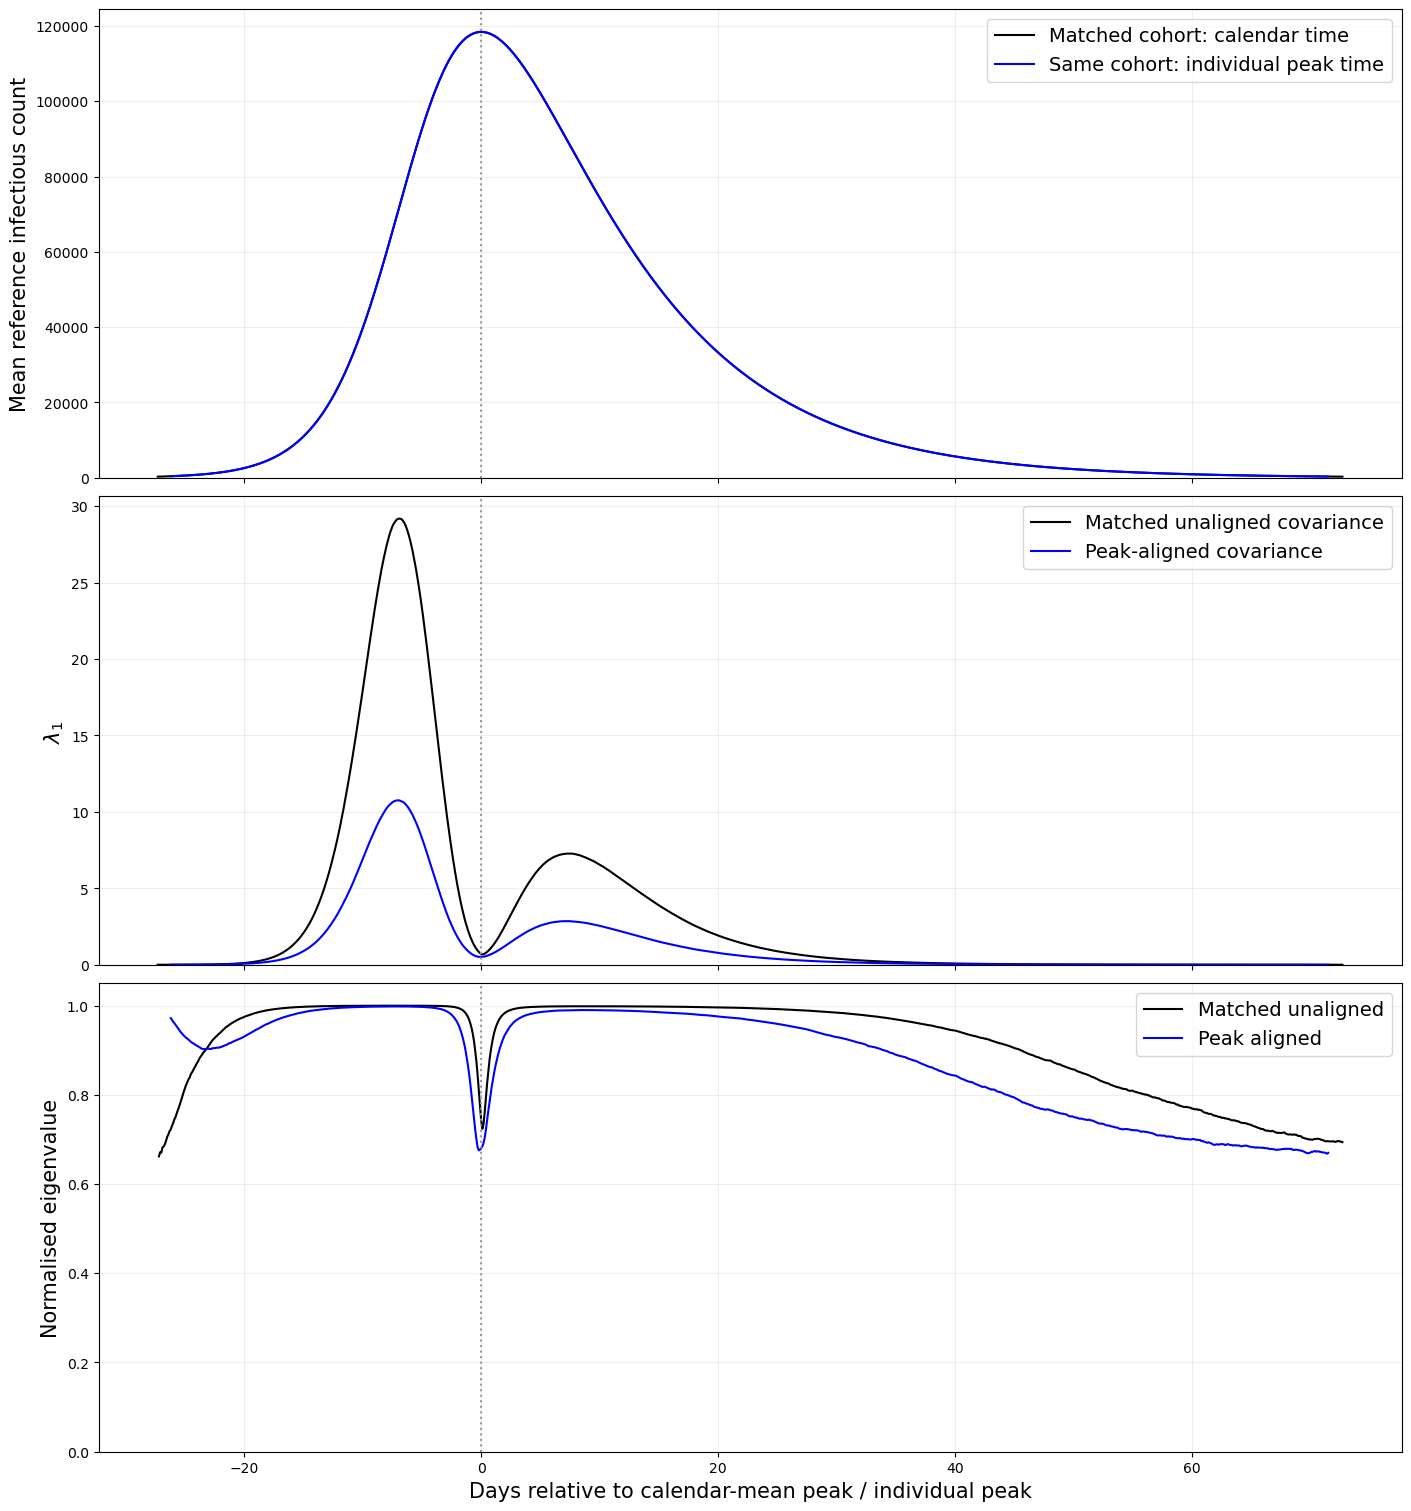

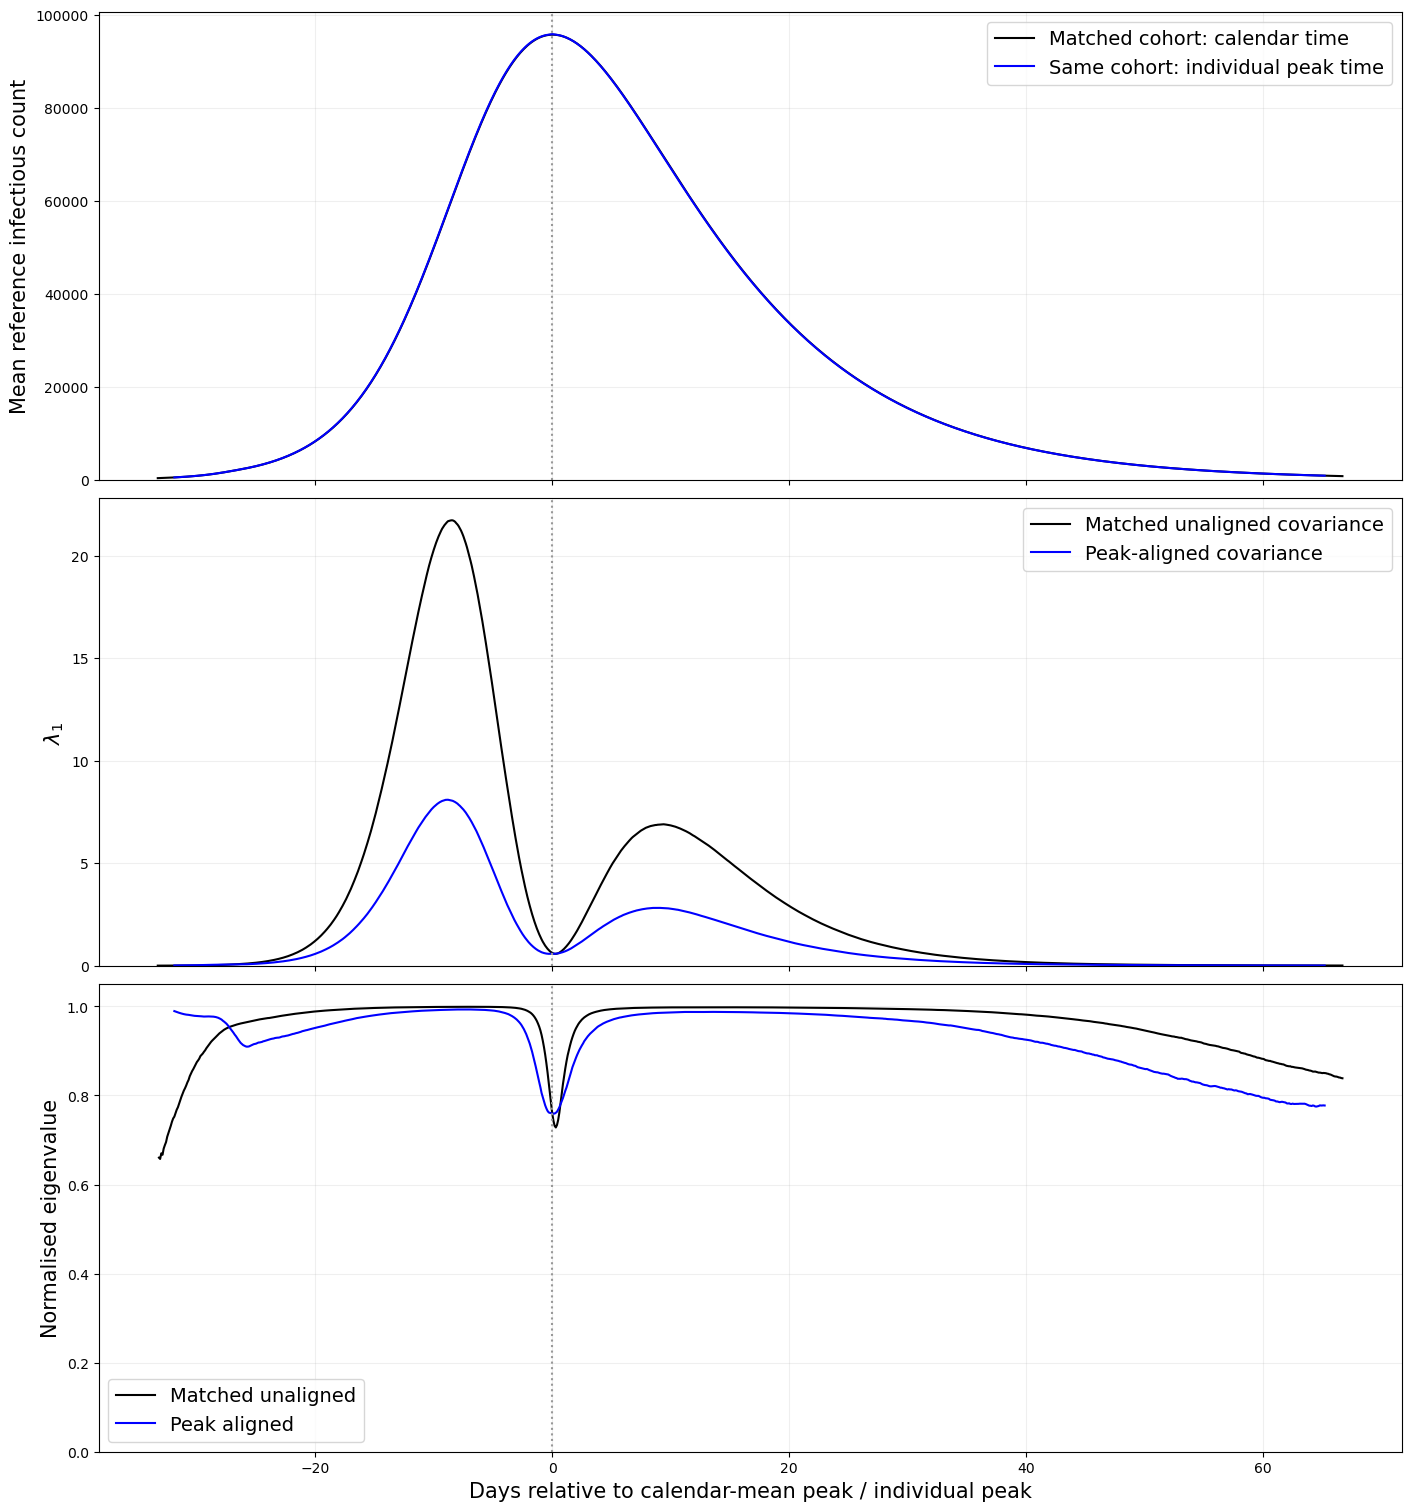

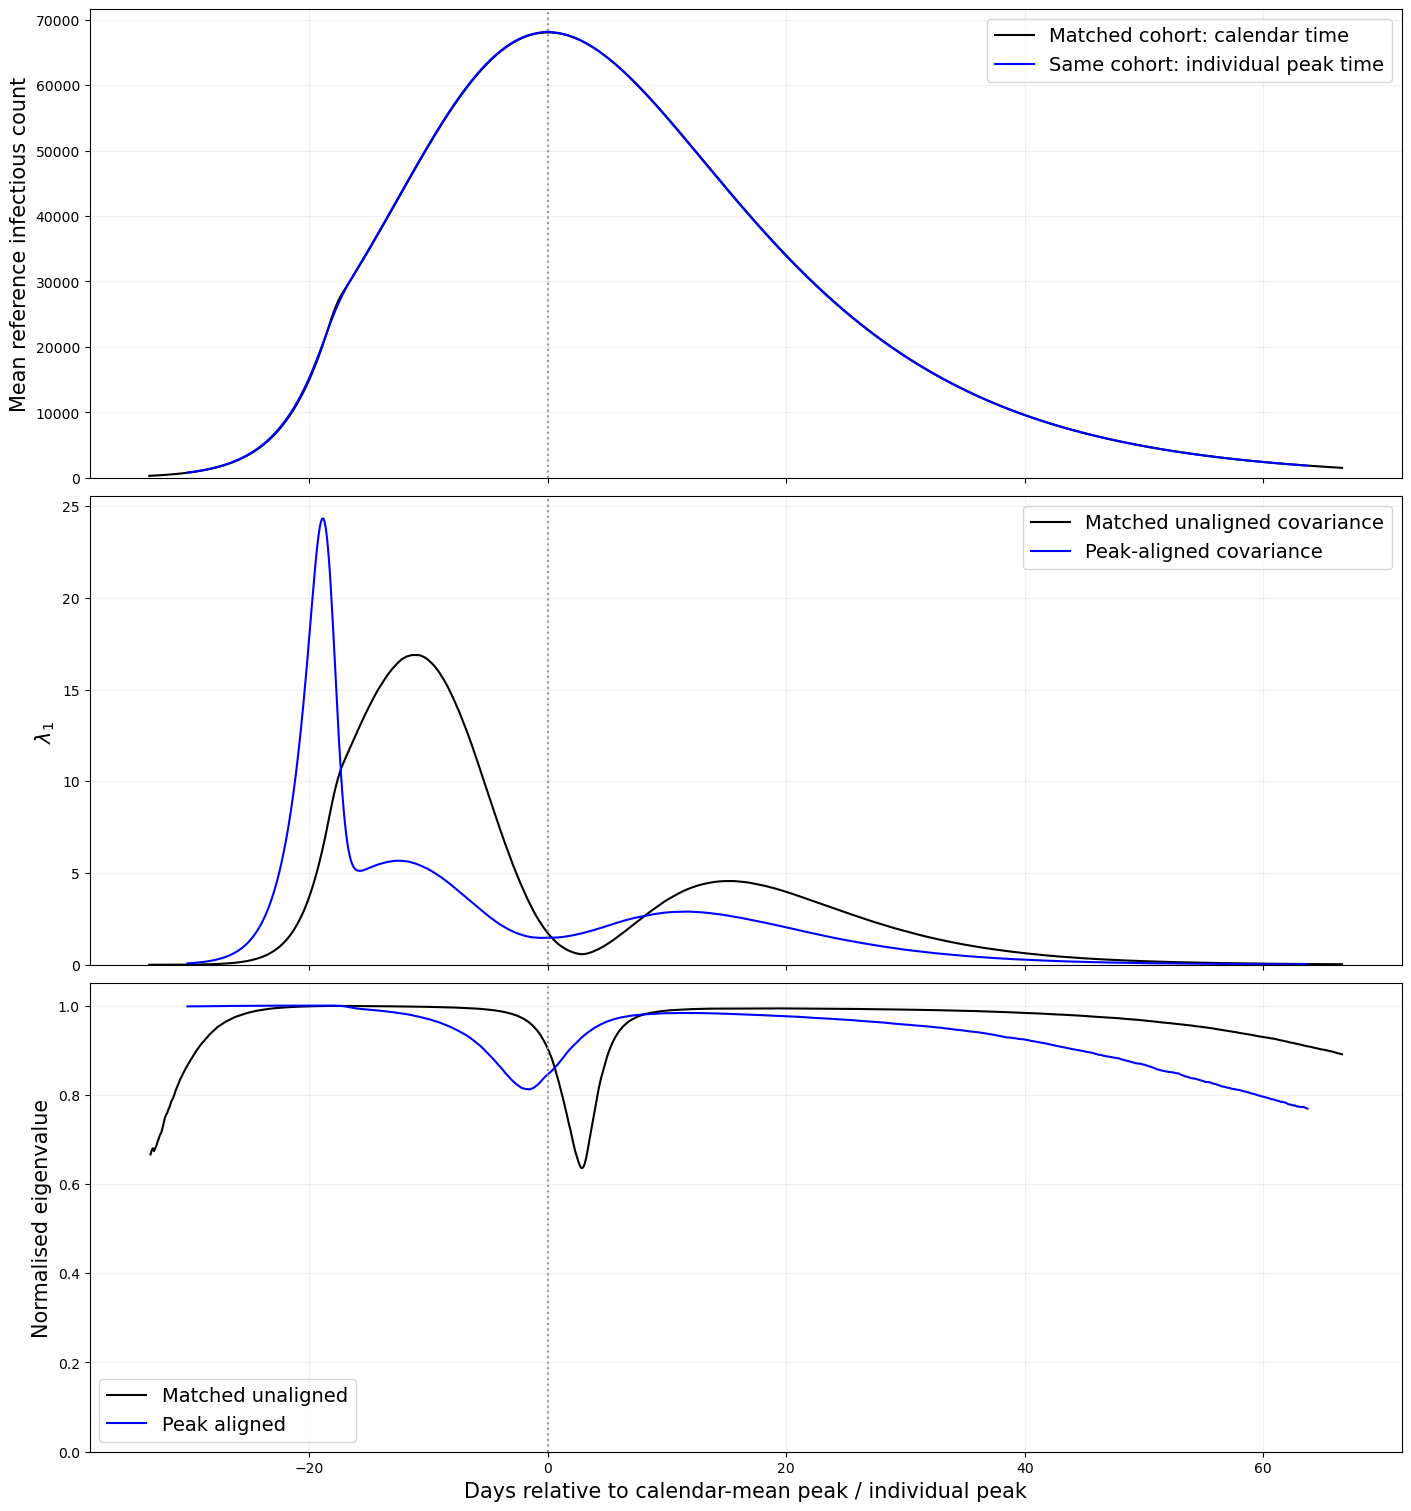

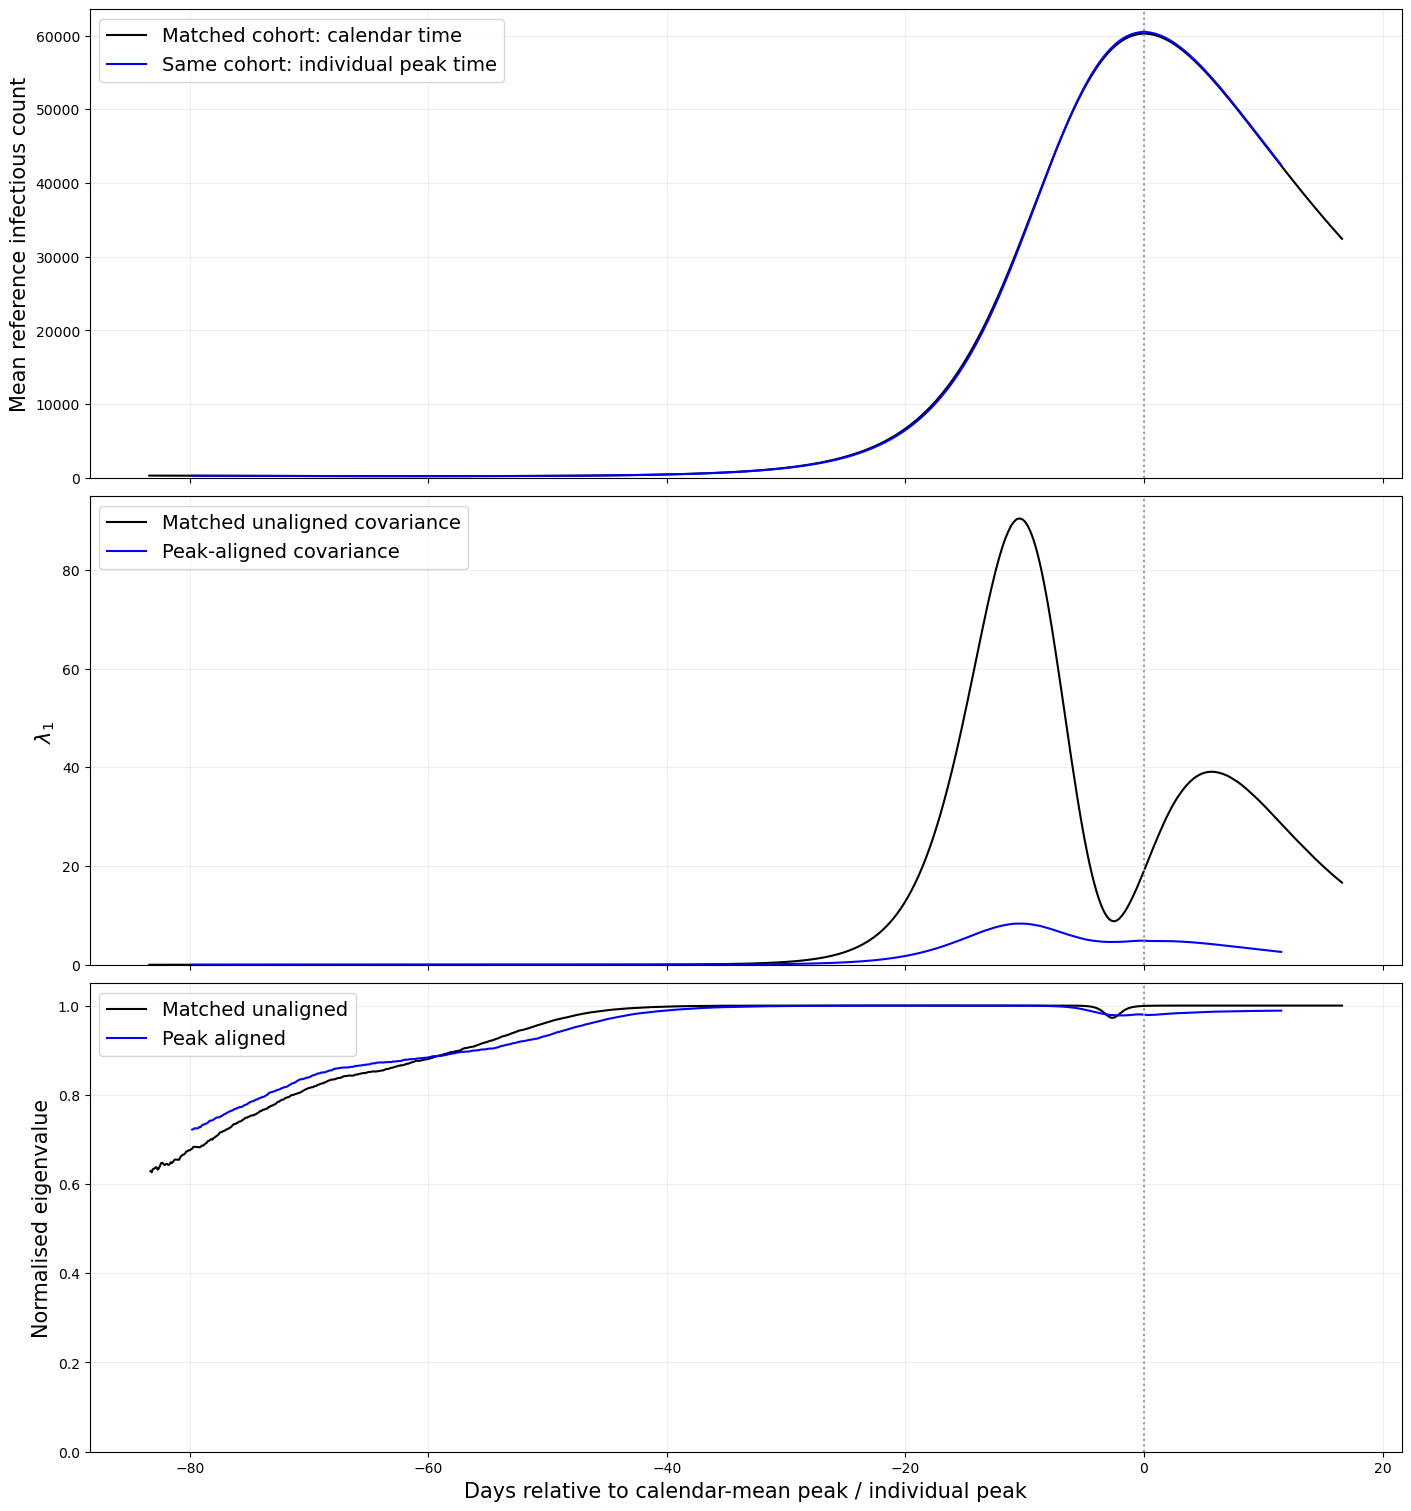

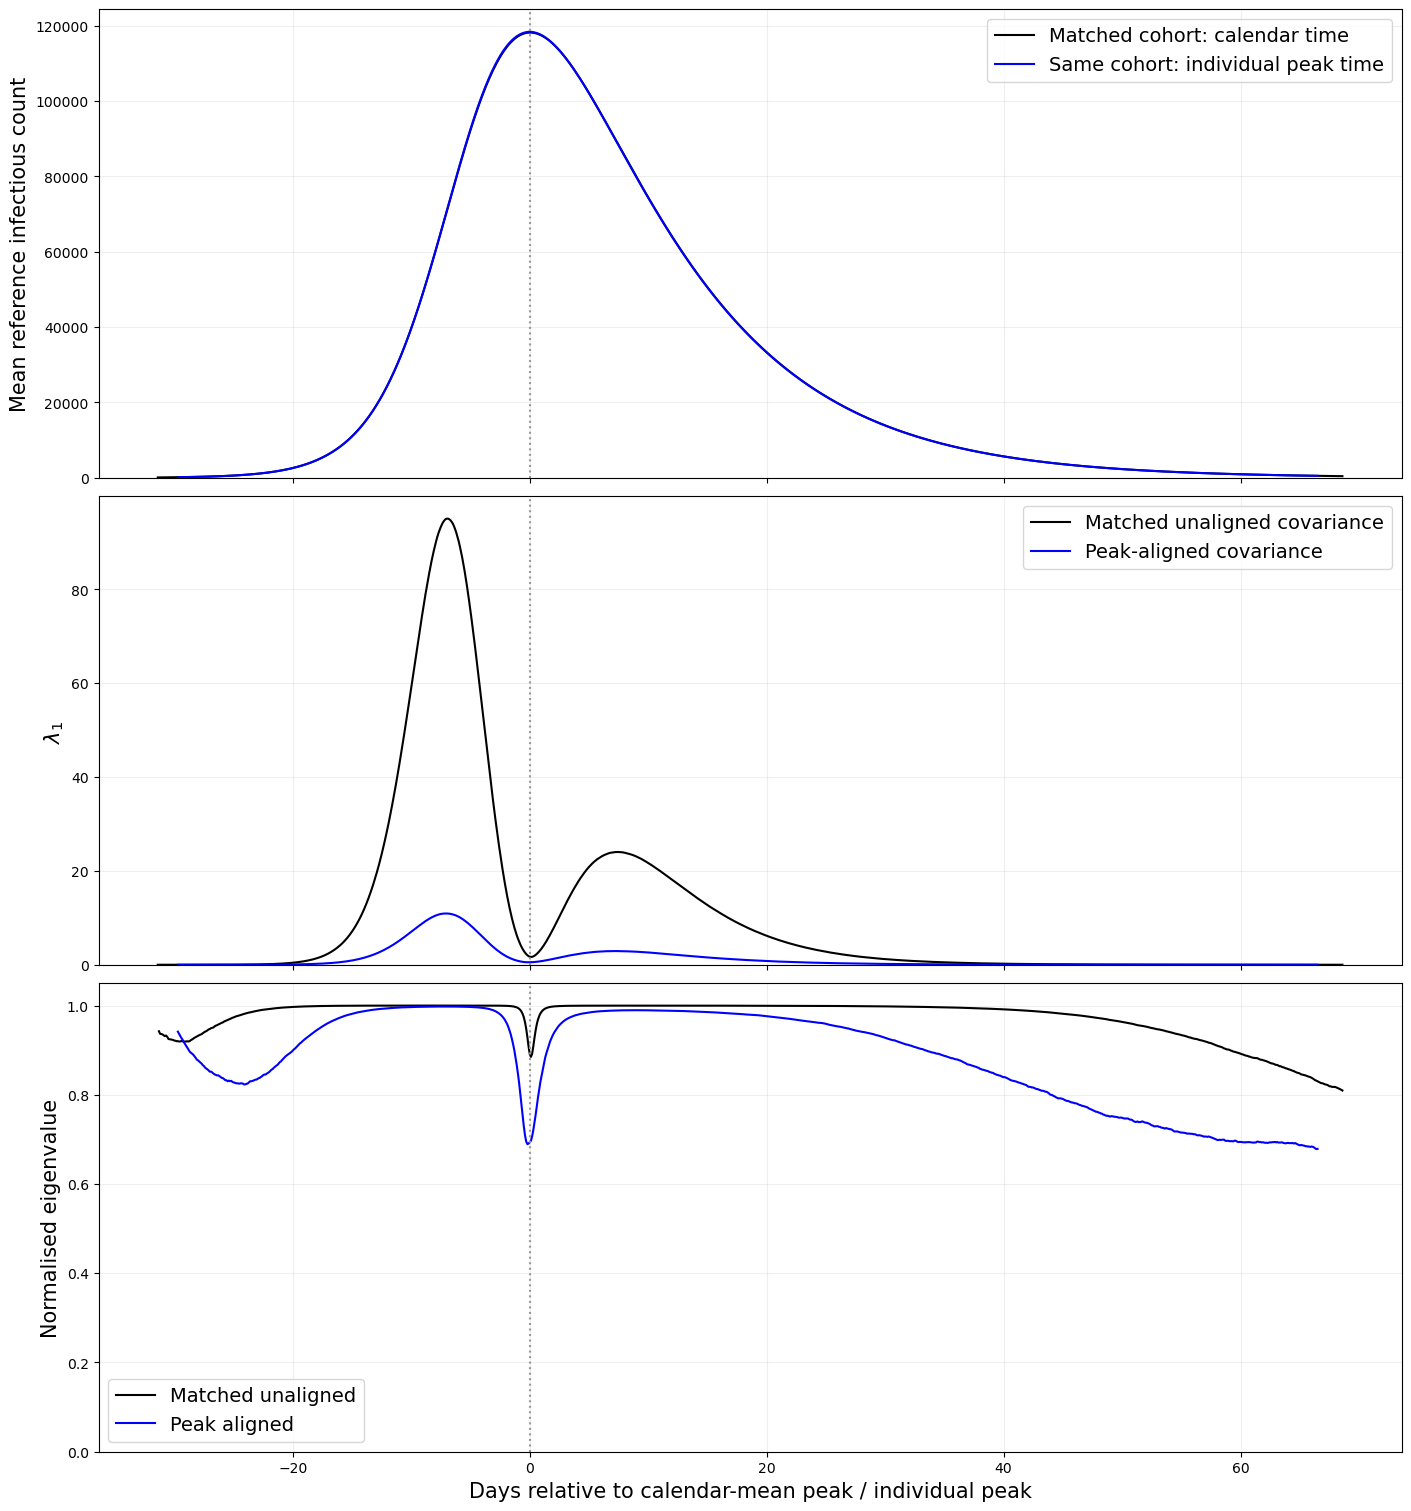

In [26]:
scenario_results = {
    "constant": results_constant
}

scenario_results = {
    "constant": results_constant,
    "indec": results_incity,
    "betdec": results_between,
    "newvar": results_nv,
    "seed": results_seed,
}


def run_review_diagnostics_align(scenarios, save_figures=True):
    for name, result in scenarios.items():
        aligned = peak_alignment_diagnostics(result)
        if save_figures:
            def figure_path(suffix):
                return (rev_figs / f"{name}_{suffix}.pdf")
            plot_peak_alignment(result, aligned, figure_path("peak_alignment"))
        else:
            plot_peak_alignment(result, aligned)
    return True

if run_review_figs:
    _ = run_review_diagnostics_align(scenario_results, save_figures=True)

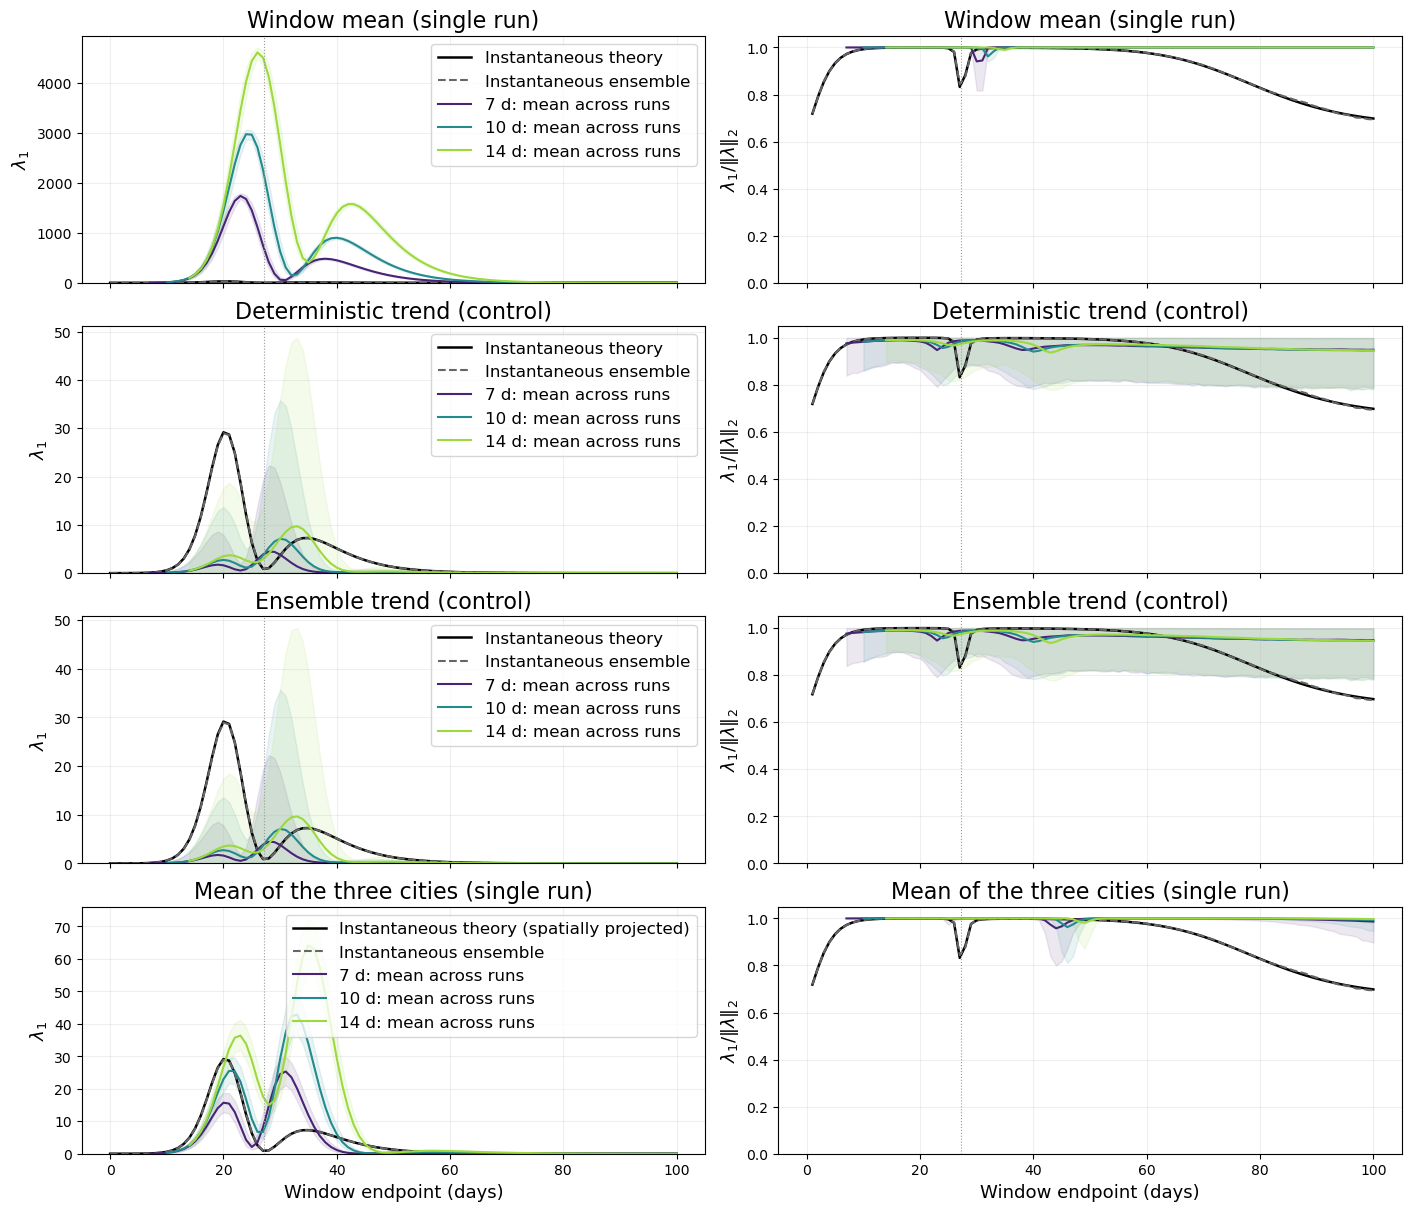

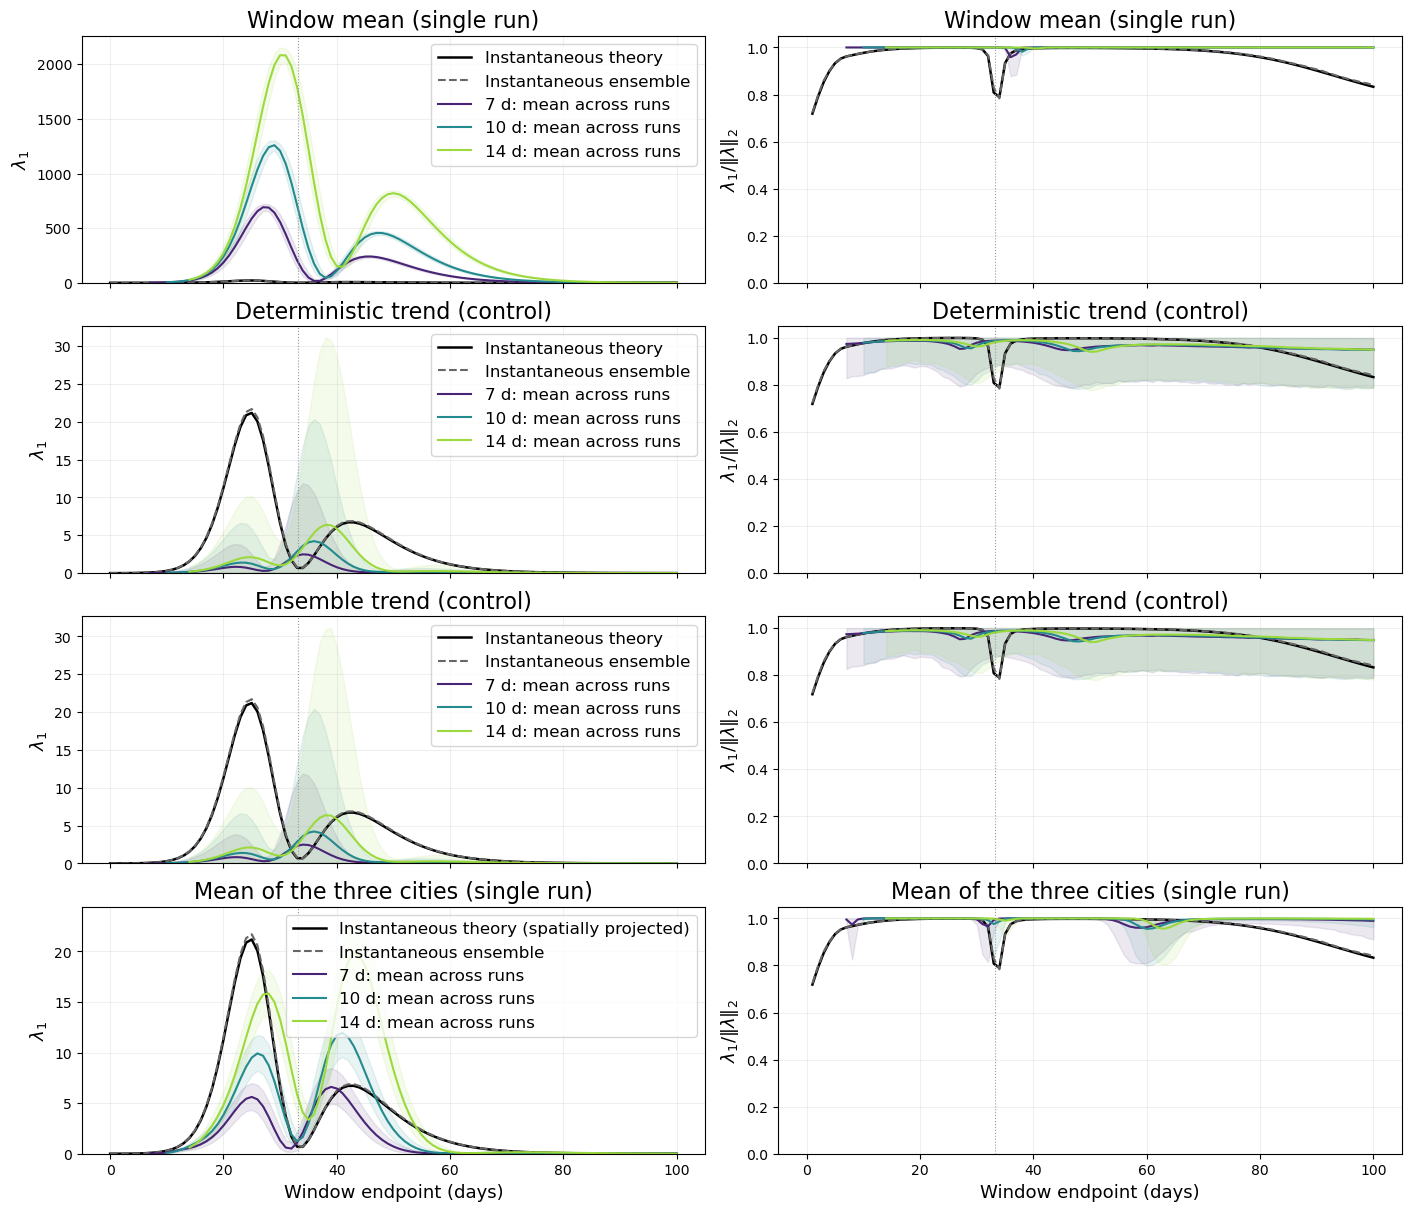

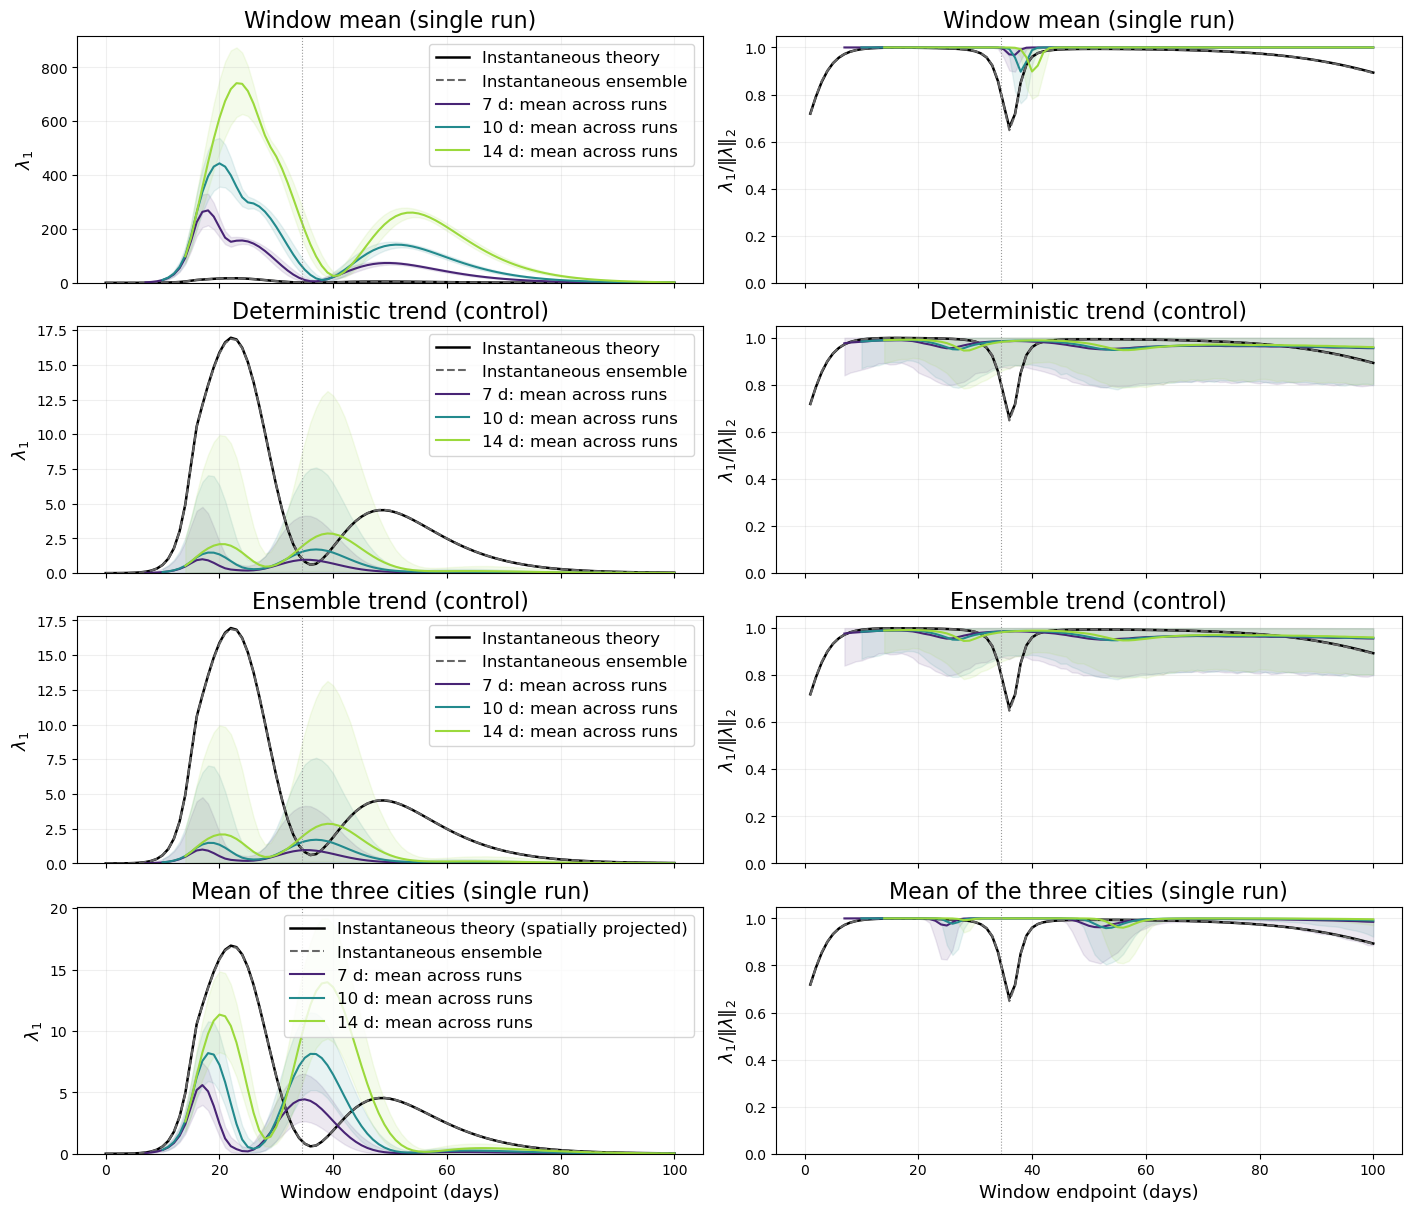

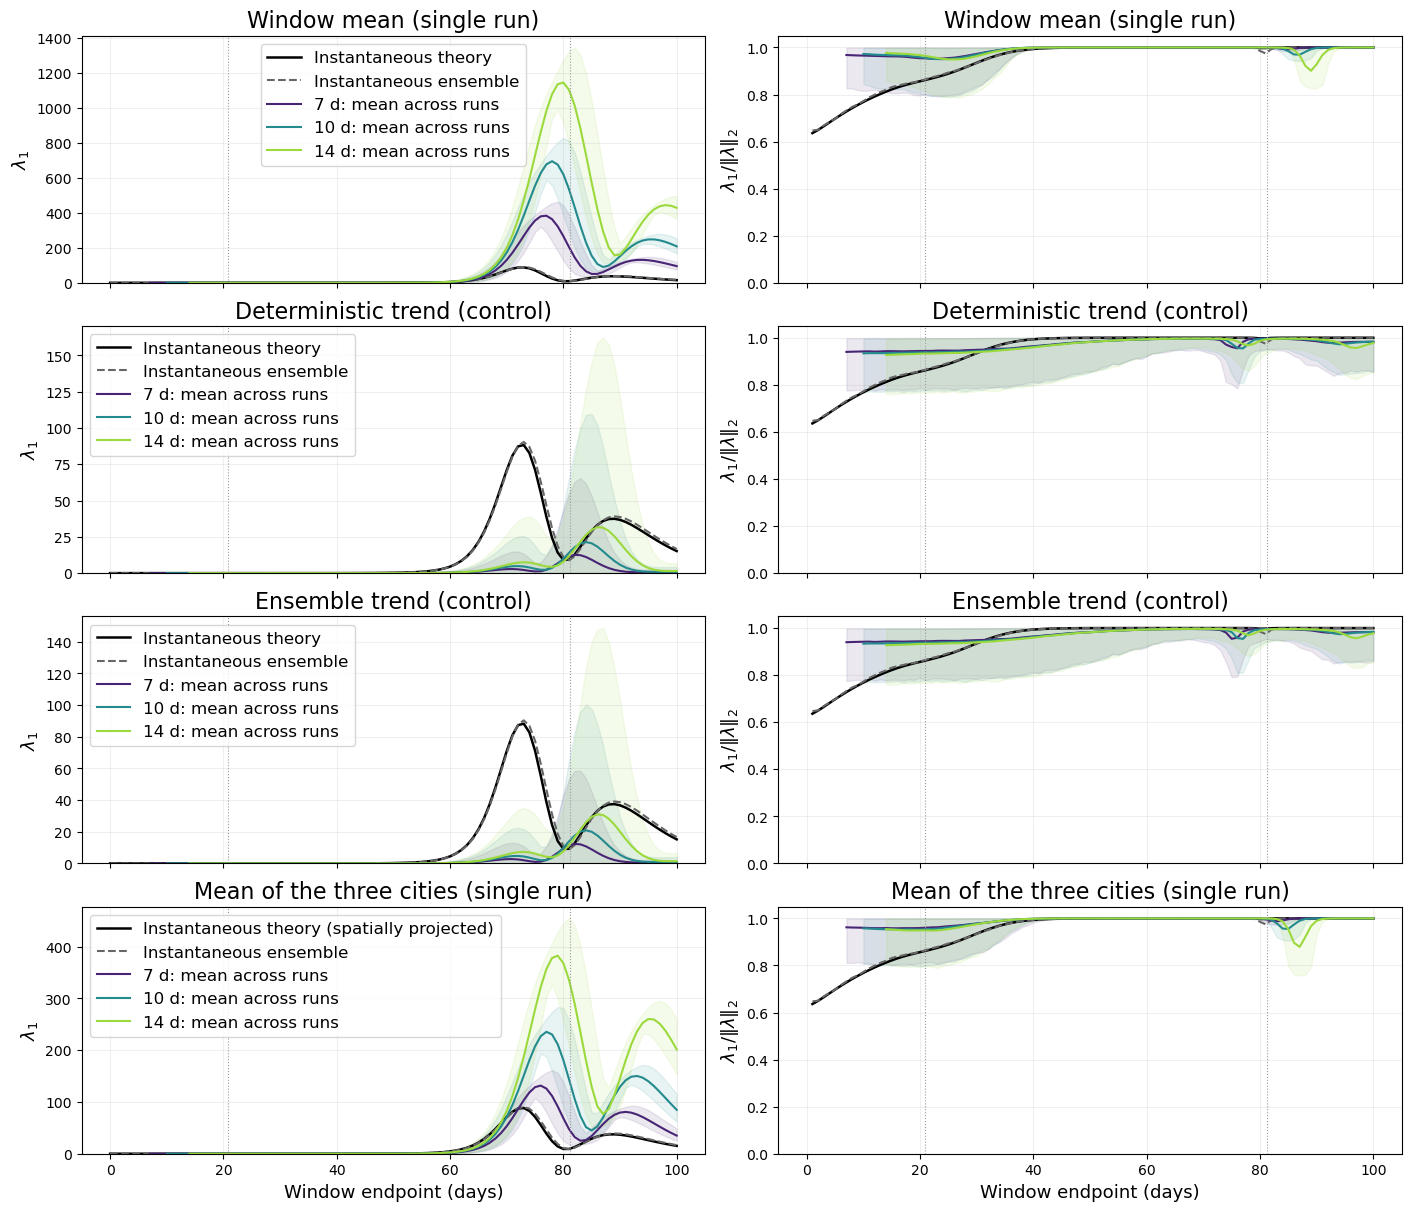

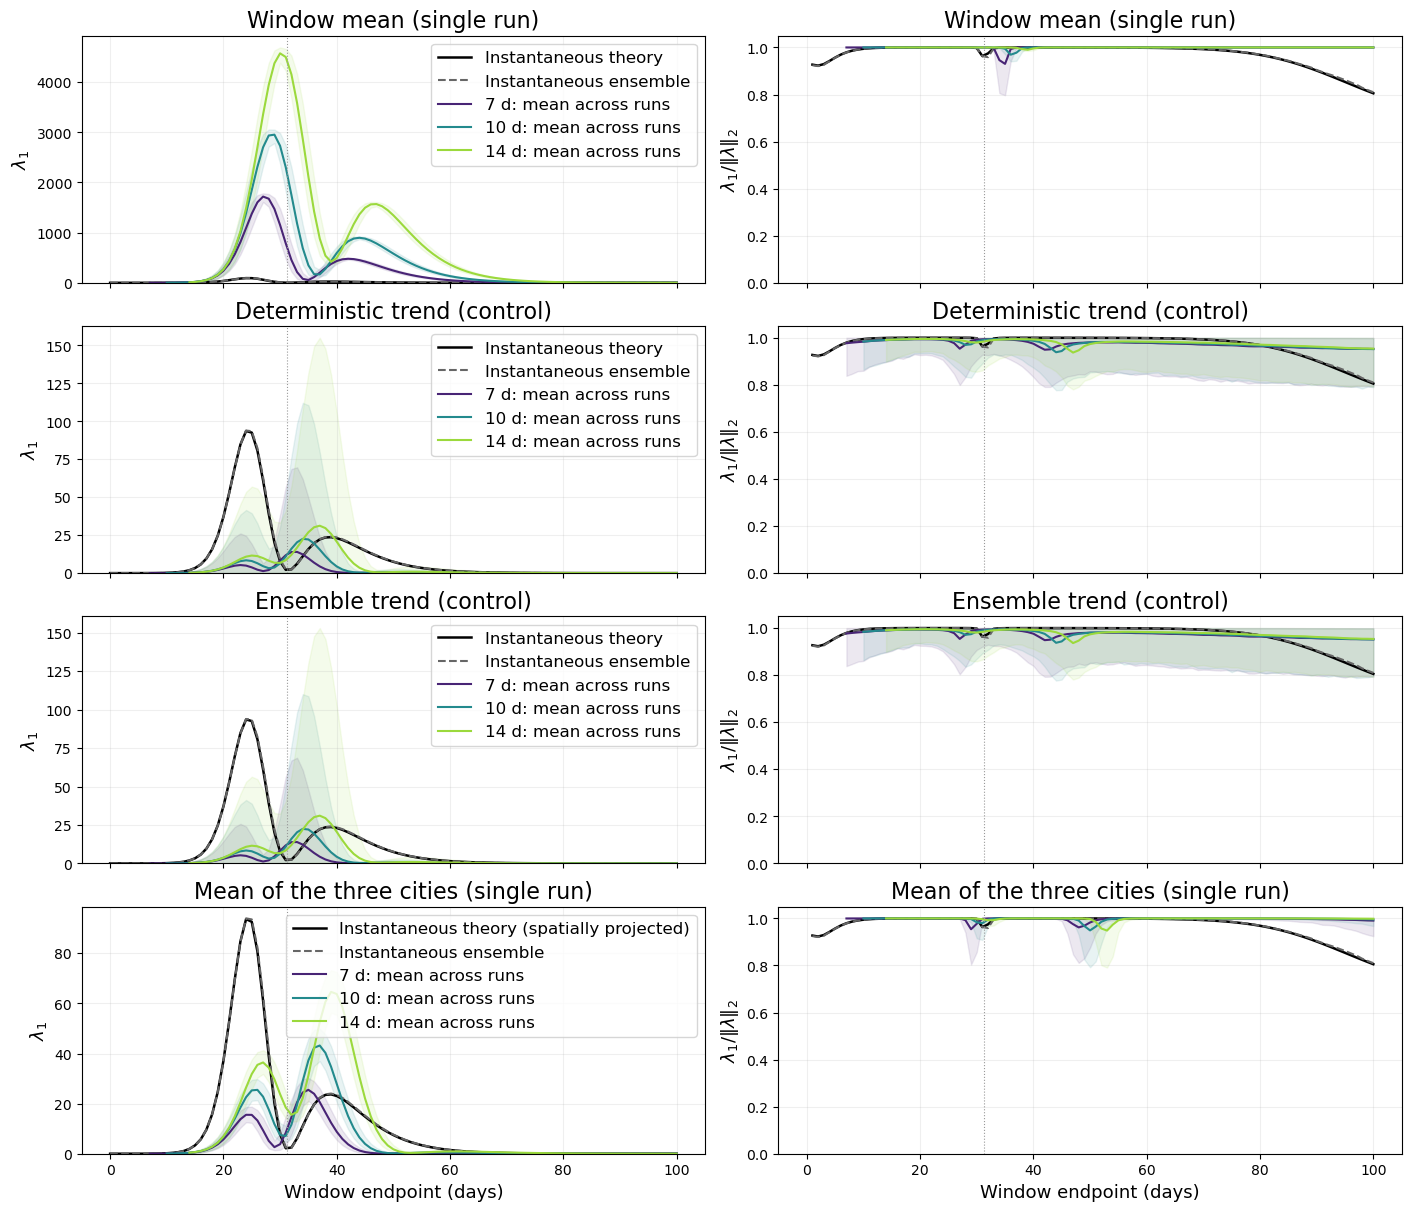

In [24]:
scenario_results = {
    "constant": results_constant
}

scenario_results = {
    "constant": results_constant,
    "indec": results_incity,
    "betdec": results_between,
    "newvar": results_nv,
    "seed": results_seed,
}


def run_review_diagnostics_rolling(scenarios, save_figures=True):
    for name, result in scenarios.items():
        rolling = rolling_covariance_diagnostics(result)
        if save_figures:
            def figure_path(suffix):
                return (rev_figs / f"{name}_{suffix}.pdf")
            plot_rolling_comparison(result, rolling, figure_path("rolling"))
        else:
            plot_rolling_comparison(result, rolling)
    return True

if run_review_figs:
    _ = run_review_diagnostics_rolling(scenario_results, save_figures=True)